# PDAN8412w POE Part 2: Logistic Regression from Scratch

## Predicting Book Bestseller Status

**Module:** Programming for Data Analytics 2 (PDAN8412w)  
**Assessment:** Part 2 – Logistic Regression from Scratch  

### Project Overview
The objective of this analysis is to develop a binary Logistic Regression classification algorithm from scratch using Python. The model will investigate whether available book characteristics can be used to predict bestseller status.

The project will follow a structured analytical process consisting of dataset evaluation, exploratory data analysis, data cleaning, feature selection, preprocessing, model development, model evaluation, controlled model improvement and final interpretation.

The Logistic Regression learning algorithm will be implemented manually using NumPy rather than using a pre-built Logistic Regression estimator.

## 1. Environment Setup and Dataset Audit

The first stage of the analysis verifies the Python environment and loads the raw book dataset. A preliminary audit is then conducted to understand the dataset's dimensions, variables, data types and overall structure before any cleaning or modelling decisions are made.

In [1]:
# ---------------------------------------------------------
# 1. IMPORT REQUIRED LIBRARIES
# ---------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Display settings to make the dataset easier to inspect
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

print("Environment setup completed successfully.")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

Environment setup completed successfully.
NumPy version: 2.3.5
Pandas version: 2.3.3


### 1.1 Load the Raw Book Dataset

The selected dataset is loaded from the Part 2 data directory. At this stage, the dataset is kept in its original form so that its structure and quality can be assessed before any cleaning, feature engineering or modelling decisions are made.

**Dataset source: Kaggle – Books Sales and Ratings, file Books_Data_Clean.csv.**

**URL: https://www.kaggle.com/datasets/thedevastator/books-sales-and-ratings?utm_source=chatgpt.com&select=Books_Data_Clean.csv**

In [2]:
# ---------------------------------------------------------
# 2. LOAD THE RAW BOOK DATASET
# ---------------------------------------------------------

DATA_PATH = "../data/Part2/Books_Data_Clean.csv"

books_df = pd.read_csv(DATA_PATH)

# Remove accidental leading/trailing whitespace from column names
books_df.columns = books_df.columns.str.strip()

print("Dataset loaded successfully.")
print(f"Number of rows: {books_df.shape[0]:,}")
print(f"Number of columns: {books_df.shape[1]}")

books_df.head()

Dataset loaded successfully.
Number of rows: 1,070
Number of columns: 15


,index,Publishing Year,Book Name,Author,language_code,Author_Rating,Book_average_rating,Book_ratings_count,genre,gross sales,publisher revenue,sale price,sales rank,Publisher,units sold
0,0,1975.0,Beowulf,"Unknown, Seamus Heaney",en-US,Novice,3.42,155903,genre fiction,34160.0,20496.0,4.88,1,HarperCollins Publishers,7000
1,1,1987.0,Batman: Year One,"Frank Miller, David Mazzucchelli, Richmond Lew...",eng,Intermediate,4.23,145267,genre fiction,12437.5,7462.5,1.99,2,HarperCollins Publishers,6250
2,2,2015.0,Go Set a Watchman,Harper Lee,eng,Novice,3.31,138669,genre fiction,47795.0,28677.0,8.69,3,"Amazon Digital Services, Inc.",5500
3,3,2008.0,When You Are Engulfed in Flames,David Sedaris,en-US,Intermediate,4.04,150898,fiction,41250.0,24750.0,7.50,3,Hachette Book Group,5500
4,4,2011.0,Daughter of Smoke & Bone,Laini Taylor,eng,Intermediate,4.04,198283,genre fiction,37952.5,22771.5,7.99,4,Penguin Group (USA) LLC,4750


### 1.2 Initial Dataset Structure

The dimensions, variable names and data types are inspected to understand how the dataset is organised. This step helps distinguish numerical, categorical and identifier variables before deciding how each should be handled during analysis.

In [3]:
# ---------------------------------------------------------
# 3. INSPECT DATASET STRUCTURE
# ---------------------------------------------------------

print("DATASET DIMENSIONS")
print("-" * 60)
print(f"Rows: {books_df.shape[0]:,}")
print(f"Columns: {books_df.shape[1]}")

print("\nCOLUMN NAMES")
print("-" * 60)

for i, column in enumerate(books_df.columns, start=1):
    print(f"{i:>2}. {column}")

print("\nDATA TYPES")
print("-" * 60)
print(books_df.dtypes)

DATASET DIMENSIONS
------------------------------------------------------------
Rows: 1,070
Columns: 15

COLUMN NAMES
------------------------------------------------------------
 1. index
 2. Publishing Year
 3. Book Name
 4. Author
 5. language_code
 6. Author_Rating
 7. Book_average_rating
 8. Book_ratings_count
 9. genre
10. gross sales
11. publisher revenue
12. sale price
13. sales rank
14. Publisher
15. units sold

DATA TYPES
------------------------------------------------------------
index                    int64
Publishing Year        float64
Book Name               object
Author                  object
language_code           object
Author_Rating           object
Book_average_rating    float64
Book_ratings_count       int64
genre                   object
gross sales            float64
publisher revenue      float64
sale price             float64
sales rank               int64
Publisher               object
units sold               int64
dtype: object


### 1.3 Dataset Information

A more detailed structural inspection is performed to confirm the number of non-null observations in each variable and identify the amount of memory used by the dataset.

In [4]:
# ---------------------------------------------------------
# 4. DISPLAY DATASET INFORMATION
# ---------------------------------------------------------

books_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1070 entries, 0 to 1069
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   index                1070 non-null   int64  
 1   Publishing Year      1069 non-null   float64
 2   Book Name            1047 non-null   object 
 3   Author               1070 non-null   object 
 4   language_code        1017 non-null   object 
 5   Author_Rating        1070 non-null   object 
 6   Book_average_rating  1070 non-null   float64
 7   Book_ratings_count   1070 non-null   int64  
 8   genre                1070 non-null   object 
 9   gross sales          1070 non-null   float64
 10  publisher revenue    1070 non-null   float64
 11  sale price           1070 non-null   float64
 12  sales rank           1070 non-null   int64  
 13  Publisher            1070 non-null   object 
 14  units sold           1070 non-null   int64  
dtypes: float64(5), int64(4), object(6)
mem

### 1.4 Preliminary Column Audit

The dataset is checked for automatically generated index columns that may have been introduced when the CSV file was originally exported. Such columns do not contain meaningful book characteristics and would not be suitable predictors.

In [5]:
# ---------------------------------------------------------
# 5. CHECK FOR AUTOMATICALLY GENERATED INDEX COLUMNS
# ---------------------------------------------------------

unnamed_columns = [
    column for column in books_df.columns
    if str(column).lower().startswith("unnamed")
]

if unnamed_columns:
    print("Potential index columns detected:")
    for column in unnamed_columns:
        print(f"- {column}")
else:
    print("No automatically generated 'Unnamed' columns were detected.")

No automatically generated 'Unnamed' columns were detected.


### 1.5 Missing-Value Audit

Missing values are examined because incomplete observations can affect both exploratory analysis and Logistic Regression training. The number and percentage of missing values are calculated for every variable.

In [6]:
# ---------------------------------------------------------
# 6. CHECK MISSING VALUES
# ---------------------------------------------------------

missing_count = books_df.isnull().sum()
missing_percentage = (
    books_df.isnull().sum() / len(books_df) * 100
).round(2)

missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage
})

print("MISSING-VALUE SUMMARY")
print("-" * 60)

display(
    missing_summary.sort_values(
        by="Missing Values",
        ascending=False
    )
)

MISSING-VALUE SUMMARY
------------------------------------------------------------


,Missing Values,Missing Percentage
language_code,53,4.95
Book Name,23,2.15
Publishing Year,1,0.09
index,0,0.00
Author,0,0.00
Author_Rating,0,0.00
Book_average_rating,0,0.00
Book_ratings_count,0,0.00
genre,0,0.00
gross sales,0,0.00


### 1.6 Duplicate-Record Audit

Duplicate observations are checked because repeated records can distort descriptive statistics and cause individual books to influence the model more than once.

In [7]:
# ---------------------------------------------------------
# 7. CHECK DUPLICATED RECORDS
# ---------------------------------------------------------

complete_duplicates = books_df.duplicated().sum()

print("DUPLICATE AUDIT")
print("-" * 60)
print(f"Completely duplicated rows: {complete_duplicates}")
print(f"Percentage of duplicated rows: {(complete_duplicates / len(books_df) * 100):.2f}%")

DUPLICATE AUDIT
------------------------------------------------------------
Completely duplicated rows: 0
Percentage of duplicated rows: 0.00%


### 1.7 Numerical Variable Summary

Descriptive statistics are generated for the numerical variables to identify their central tendencies, ranges, variability and any values that may require further investigation. Differences in feature scale are also important because the Logistic Regression algorithm will later be trained using gradient descent.

In [8]:
# ---------------------------------------------------------
# 8. SUMMARY STATISTICS FOR NUMERICAL VARIABLES
# ---------------------------------------------------------

numerical_summary = books_df.describe().T

display(numerical_summary)

,count,mean,std,min,25%,50%,75%,max
index,1070.0,534.500000,309.026698,0.00,267.250,534.500,801.7500,1069.00
Publishing Year,1069.0,1971.377923,185.080257,-560.00,1985.000,2003.000,2010.0000,2016.00
Book_average_rating,1070.0,4.007000,0.247244,2.97,3.850,4.015,4.1700,4.77
Book_ratings_count,1070.0,94909.913084,31513.242518,27308.00,70398.000,89309.000,113906.5000,206792.00
gross sales,1070.0,1856.622944,3936.924240,104.94,372.465,809.745,1487.9575,47795.00
publisher revenue,1070.0,843.281030,2257.596743,0.00,0.000,273.078,721.1805,28677.00
sale price,1070.0,4.869561,3.559919,0.99,1.990,3.990,6.9900,33.86
sales rank,1070.0,611.652336,369.849830,1.00,287.500,595.500,932.5000,1273.00
units sold,1070.0,9676.980374,15370.571306,106.00,551.250,3924.000,5312.2500,61560.00


### 1.8 Categorical Variable Cardinality

Categorical variables are inspected according to the number of unique values they contain. Variables with very high cardinality, such as individual book titles or author names, may not be suitable for direct one-hot encoding because they can create a large number of model features relative to the dataset size.

In [9]:
# ---------------------------------------------------------
# 9. INSPECT CATEGORICAL VARIABLE CARDINALITY
# ---------------------------------------------------------

categorical_columns = books_df.select_dtypes(
    include=["object", "category"]
).columns

print("CATEGORICAL VARIABLE CARDINALITY")
print("-" * 60)

for column in categorical_columns:
    unique_count = books_df[column].nunique(dropna=False)
    print(f"{column:<30} {unique_count:>5} unique values")

CATEGORICAL VARIABLE CARDINALITY
------------------------------------------------------------
Book Name                       1046 unique values
Author                           735 unique values
language_code                      9 unique values
Author_Rating                      4 unique values
genre                              4 unique values
Publisher                          9 unique values


### 1.9 Candidate Sales and Performance Variables

Variables relating directly to book sales and commercial performance are inspected separately. These variables may help define the binary bestseller target; however, any variable used to construct or directly reveal the target must later be excluded from the predictor set to prevent target leakage.

In [10]:
# ---------------------------------------------------------
# 10. IDENTIFY SALES-RELATED VARIABLES
# ---------------------------------------------------------

sales_keywords = [
    "sale",
    "sales",
    "sold",
    "revenue",
    "rank",
    "price"
]

sales_related_columns = [
    column for column in books_df.columns
    if any(keyword in str(column).lower() for keyword in sales_keywords)
]

print("POTENTIAL SALES-RELATED VARIABLES")
print("-" * 60)

for column in sales_related_columns:
    print(f"- {column}")

POTENTIAL SALES-RELATED VARIABLES
------------------------------------------------------------
- gross sales
- publisher revenue
- sale price
- sales rank
- units sold


In [11]:
# ---------------------------------------------------------
# 11. SUMMARISE SALES-RELATED VARIABLES
# ---------------------------------------------------------

for column in sales_related_columns:
    
    print("\n" + "=" * 70)
    print(f"VARIABLE: {column}")
    print("=" * 70)
    
    print(f"Data type: {books_df[column].dtype}")
    print(f"Missing values: {books_df[column].isnull().sum()}")
    print(f"Unique values: {books_df[column].nunique(dropna=False)}")
    
    if pd.api.types.is_numeric_dtype(books_df[column]):
        display(books_df[column].describe().to_frame().T)
    else:
        display(books_df[column].value_counts(dropna=False).head(10))


VARIABLE: gross sales
Data type: float64
Missing values: 0
Unique values: 831


,count,mean,std,min,25%,50%,75%,max
gross sales,1070.0,1856.622944,3936.92424,104.94,372.465,809.745,1487.9575,47795.0



VARIABLE: publisher revenue
Data type: float64
Missing values: 0
Unique values: 610


,count,mean,std,min,25%,50%,75%,max
publisher revenue,1070.0,843.28103,2257.596743,0.0,0.0,273.078,721.1805,28677.0



VARIABLE: sale price
Data type: float64
Missing values: 0
Unique values: 149


,count,mean,std,min,25%,50%,75%,max
sale price,1070.0,4.869561,3.559919,0.99,1.99,3.99,6.99,33.86



VARIABLE: sales rank
Data type: int64
Missing values: 0
Unique values: 865


,count,mean,std,min,25%,50%,75%,max
sales rank,1070.0,611.652336,369.84983,1.0,287.5,595.5,932.5,1273.0



VARIABLE: units sold
Data type: int64
Missing values: 0
Unique values: 491


,count,mean,std,min,25%,50%,75%,max
units sold,1070.0,9676.980374,15370.571306,106.0,551.25,3924.0,5312.25,61560.0


### 1.10 Investigation of Potential Data-Quality Issues

The initial audit identified two variables requiring further investigation. The `index` variable may simply represent the row number rather than a meaningful book characteristic, while `Publishing Year` contains at least one implausible value. These issues are examined before any records or variables are removed.

In [12]:
# ---------------------------------------------------------
# 12. INVESTIGATE INDEX AND PUBLISHING YEAR
# ---------------------------------------------------------

print("INDEX VARIABLE CHECK")
print("-" * 60)

expected_index = np.arange(len(books_df))

is_sequential_index = np.array_equal(
    books_df["index"].to_numpy(),
    expected_index
)

print(f"Index runs sequentially from 0 to {len(books_df) - 1}: {is_sequential_index}")
print(f"Index unique values: {books_df['index'].nunique():,}")


print("\nPUBLISHING YEAR AUDIT")
print("-" * 60)

print(f"Missing publishing years: {books_df['Publishing Year'].isnull().sum()}")
print(f"Minimum publishing year: {books_df['Publishing Year'].min()}")
print(f"Maximum publishing year: {books_df['Publishing Year'].max()}")

invalid_years = books_df[
    (books_df["Publishing Year"].notna()) &
    (
        (books_df["Publishing Year"] < 1900) |
        (books_df["Publishing Year"] > 2026)
    )
]

print(f"\nRecords outside the plausible 1900–2026 range: {len(invalid_years)}")

display(
    invalid_years[
        [
            "Book Name",
            "Author",
            "Publishing Year",
            "genre",
            "Publisher"
        ]
    ]
)

INDEX VARIABLE CHECK
------------------------------------------------------------
Index runs sequentially from 0 to 1069: True
Index unique values: 1,070

PUBLISHING YEAR AUDIT
------------------------------------------------------------
Missing publishing years: 1
Minimum publishing year: -560.0
Maximum publishing year: 2016.0

Records outside the plausible 1900–2026 range: 60


,Book Name,Author,Publishing Year,genre,Publisher
16,The War of the Worlds,"H.G. Wells, Arthur C. Clarke",1897.0,genre fiction,"Amazon Digital Services, Inc."
28,Tess of the d'Urbervilles: A Pure Woman Faithf...,"Thomas Hardy, Tim Dolin, Margaret R. Higonnet",1891.0,nonfiction,Hachette Book Group
29,Madame Bovary,"Gustave Flaubert, Margaret Mauldon, Malcolm Bo...",1856.0,genre fiction,"Amazon Digital Services, Inc."
45,Candide,Voltaire,1759.0,genre fiction,"Amazon Digital Services, Inc."
59,David Copperfield,"Charles Dickens, Jeremy Tambling",1849.0,genre fiction,Hachette Book Group
66,Don Quijote de La Mancha,"Miguel de Cervantes Saavedra, Roberto GonzÃ¡le...",1605.0,genre fiction,Hachette Book Group
108,Heidi,"Johanna Spyri, Angelo Rinaldi, Beverly Cleary",1880.0,genre fiction,Penguin Group (USA) LLC
115,Tales of Caunterbury,"Geoffrey Chaucer, Nevill Coghill",1390.0,genre fiction,"Amazon Digital Services, Inc."
119,Uncle Tom's Cabin or Life Among the Lowly,Harriet Beecher Stowe,1852.0,fiction,HarperCollins Publishers
168,Vingt Mille Lieues Sous les Mers,"Jules Verne, Anthony Bonner",1869.0,genre fiction,"Amazon Digital Services, Inc."


### 1.11 Investigation of Missing Metadata

The initial audit found missing values in `Book Name`, `language_code` and `Publishing Year`. The affected records are examined to determine whether missingness occurs in variables required for modelling and whether observations should be removed, retained or assigned an explicit unknown category.

In [13]:
# ---------------------------------------------------------
# 13. INSPECT RECORDS WITH MISSING VALUES
# ---------------------------------------------------------

columns_with_missing = [
    "Book Name",
    "language_code",
    "Publishing Year"
]

for column in columns_with_missing:
    
    missing_rows = books_df[books_df[column].isnull()]
    
    print("\n" + "=" * 70)
    print(f"MISSING VARIABLE: {column}")
    print(f"Number of affected records: {len(missing_rows)}")
    print("=" * 70)
    
    display(
        missing_rows[
            [
                "Book Name",
                "Author",
                "Publishing Year",
                "language_code",
                "Author_Rating",
                "genre",
                "Publisher",
                "units sold"
            ]
        ].head(10)
    )


MISSING VARIABLE: Book Name
Number of affected records: 23


,Book Name,Author,Publishing Year,language_code,Author_Rating,genre,Publisher,units sold
24,NaN,"Kenneth Branagh, William Shakespeare",1996.0,eng,Intermediate,genre fiction,"Amazon Digital Services, Inc.",2666
34,NaN,Brandon Sanderson,2007.0,eng,Intermediate,genre fiction,Random House LLC,2000
105,NaN,Mark Cotta Vaz,2011.0,eng,Intermediate,genre fiction,Penguin Group (USA) LLC,960
186,NaN,Kate Egan,2012.0,en-US,Famous,genre fiction,HarperCollins Publishers,491
190,NaN,Allie Brosh,2013.0,eng,Intermediate,genre fiction,Penguin Group (USA) LLC,483
245,NaN,Phaidon Press,1997.0,eng,Intermediate,genre fiction,Penguin Group (USA) LLC,383
312,NaN,E.L. James,2012.0,NaN,Excellent,genre fiction,"Amazon Digital Services, Inc.",278
359,NaN,Isaac Asimov,1953.0,eng,Excellent,nonfiction,HarperCollins Publishers,6237
440,NaN,"Marcus Pfister, J. Alison James",1995.0,en-US,Excellent,genre fiction,"Amazon Digital Services, Inc.",4887
445,NaN,"Robert Kapilow, Dr. Seuss",NaN,NaN,Famous,nonfiction,Hachette Book Group,4806



MISSING VARIABLE: language_code
Number of affected records: 53


,Book Name,Author,Publishing Year,language_code,Author_Rating,genre,Publisher,units sold
22,Needful Things,Stephen King,1991.0,NaN,Intermediate,genre fiction,"Amazon Digital Services, Inc.",2800
74,"Are You There, Vodka? It's Me, Chelsea",Chelsea Handler,2007.0,NaN,Intermediate,genre fiction,Hachette Book Group,1369
109,Prey,Michael Crichton,2002.0,NaN,Intermediate,genre fiction,"Amazon Digital Services, Inc.",930
207,Mrs. Frisby and the Rats of NIMH,Robert C. O'Brien,1971.0,NaN,Intermediate,genre fiction,"Amazon Digital Services, Inc.",455
209,The Little House Collection,"Laura Ingalls Wilder, Garth Williams",1953.0,NaN,Intermediate,genre fiction,Random House LLC,453
210,The Girls' Guide to Hunting and Fishing,Melissa Bank,1998.0,NaN,Novice,nonfiction,"Amazon Digital Services, Inc.",453
256,Sh*t My Dad Says,Justin Halpern,2010.0,NaN,Intermediate,nonfiction,Hachette Book Group,370
259,The Four Agreements: A Practical Guide to Pers...,Miguel Ruiz,1997.0,NaN,Intermediate,genre fiction,Penguin Group (USA) LLC,366
267,"One Fish, Two Fish, Red Fish, Blue Fish",Dr. Seuss,1960.0,NaN,Intermediate,nonfiction,Simon and Schuster Digital Sales Inc,355
268,Watchers,Dean Koontz,1987.0,NaN,Intermediate,genre fiction,"Amazon Digital Services, Inc.",351



MISSING VARIABLE: Publishing Year
Number of affected records: 1


,Book Name,Author,Publishing Year,language_code,Author_Rating,genre,Publisher,units sold
445,NaN,"Robert Kapilow, Dr. Seuss",NaN,NaN,Famous,nonfiction,Hachette Book Group,4806


### 1.12 Distribution of Candidate Categorical Features

Low-cardinality categorical variables are examined in more detail to identify rare categories, inconsistent labels and potential preprocessing requirements. These variables may later be encoded for use in the Logistic Regression model.

In [14]:
# ---------------------------------------------------------
# 14. INSPECT CATEGORICAL FEATURE DISTRIBUTIONS
# ---------------------------------------------------------

candidate_categorical_features = [
    "language_code",
    "Author_Rating",
    "genre",
    "Publisher"
]

for column in candidate_categorical_features:
    
    counts = books_df[column].value_counts(dropna=False)
    percentages = (
        books_df[column]
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .round(2)
    )
    
    summary = pd.DataFrame({
        "Count": counts,
        "Percentage": percentages
    })
    
    print("\n" + "=" * 70)
    print(f"VARIABLE: {column}")
    print("=" * 70)
    
    display(summary)


VARIABLE: language_code


,Count,Percentage
language_code,,
eng,737,68.88
en-US,234,21.87
NaN,53,4.95
en-GB,30,2.80
en-CA,7,0.65
fre,4,0.37
spa,2,0.19
ara,2,0.19
nl,1,0.09



VARIABLE: Author_Rating


,Count,Percentage
Author_Rating,,
Intermediate,625,58.41
Excellent,362,33.83
Famous,53,4.95
Novice,30,2.80



VARIABLE: genre


,Count,Percentage
genre,,
genre fiction,822,76.82
nonfiction,171,15.98
fiction,62,5.79
children,15,1.40



VARIABLE: Publisher


,Count,Percentage
Publisher,,
"Amazon Digital Services, Inc.",600,56.07
Random House LLC,120,11.21
Penguin Group (USA) LLC,108,10.09
HarperCollins Publishers,71,6.64
Hachette Book Group,66,6.17
Simon and Schuster Digital Sales Inc,56,5.23
Macmillan,41,3.83
HarperCollins Publishing,4,0.37
HarperCollins Christian Publishing,4,0.37


### 1.13 Target-Leakage Audit

The dataset contains several measures of commercial performance. Since `units sold` is being considered as the basis for defining bestseller status, variables that are mathematically derived from sales or directly describe realised sales performance must not be used as model predictors.

These relationships are examined before the target variable is created.

In [15]:
# ---------------------------------------------------------
# 15. AUDIT SALES-RELATED VARIABLES FOR TARGET LEAKAGE
# ---------------------------------------------------------

sales_variables = [
    "units sold",
    "gross sales",
    "publisher revenue",
    "sale price",
    "sales rank"
]

sales_correlation = books_df[sales_variables].corr()

display(sales_correlation.round(3))


# Check whether gross sales is approximately:
# sale price × units sold

calculated_gross_sales = (
    books_df["sale price"] * books_df["units sold"]
)

gross_difference = (
    books_df["gross sales"] - calculated_gross_sales
).abs()

print("\nGROSS SALES RELATIONSHIP")
print("-" * 60)
print(
    "Rows where gross sales equals sale price × units sold: "
    f"{np.isclose(books_df['gross sales'], calculated_gross_sales).sum():,} "
    f"out of {len(books_df):,}"
)

print(
    f"Maximum absolute difference: "
    f"{gross_difference.max():,.4f}"
)

,units sold,gross sales,publisher revenue,sale price,sales rank
units sold,1.000,-0.151,-0.116,0.004,0.212
gross sales,-0.151,1.000,0.913,0.273,-0.442
publisher revenue,-0.116,0.913,1.000,0.314,-0.341
sale price,0.004,0.273,0.314,1.000,0.072
sales rank,0.212,-0.442,-0.341,0.072,1.000



GROSS SALES RELATIONSHIP
------------------------------------------------------------
Rows where gross sales equals sale price × units sold: 444 out of 1,070
Maximum absolute difference: 674,983.8200


### 1.14 Proposed Bestseller Definition

The source dataset does not contain a pre-existing binary bestseller label. For this analysis, bestseller status is therefore operationally defined using observed unit sales.

A book is provisionally classified as a bestseller if its `units sold` value falls within the top 25% of the dataset. This definition identifies the highest-selling quarter of the observed books while retaining a sufficiently large comparison group for binary classification.

The threshold and resulting class distribution are evaluated before the target is permanently created.

In [16]:
# ---------------------------------------------------------
# 16. EVALUATE PROPOSED BESTSELLER THRESHOLD
# ---------------------------------------------------------

bestseller_threshold = books_df["units sold"].quantile(0.75)

provisional_bestseller = (
    books_df["units sold"] > bestseller_threshold
).astype(int)

target_counts = provisional_bestseller.value_counts().sort_index()

target_percentages = (
    provisional_bestseller
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

target_summary = pd.DataFrame({
    "Class": ["Non-Bestseller", "Bestseller"],
    "Count": [
        target_counts.get(0, 0),
        target_counts.get(1, 0)
    ],
    "Percentage": [
        target_percentages.get(0, 0),
        target_percentages.get(1, 0)
    ]
})

print("PROPOSED BESTSELLER DEFINITION")
print("-" * 60)
print(f"75th percentile of units sold: {bestseller_threshold:,.2f}")

print(
    "\nDefinition: Bestseller = units sold "
    f"> {bestseller_threshold:,.2f}"
)

display(target_summary)

PROPOSED BESTSELLER DEFINITION
------------------------------------------------------------
75th percentile of units sold: 5,312.25

Definition: Bestseller = units sold > 5,312.25


,Class,Count,Percentage
0,Non-Bestseller,802,74.95
1,Bestseller,268,25.05


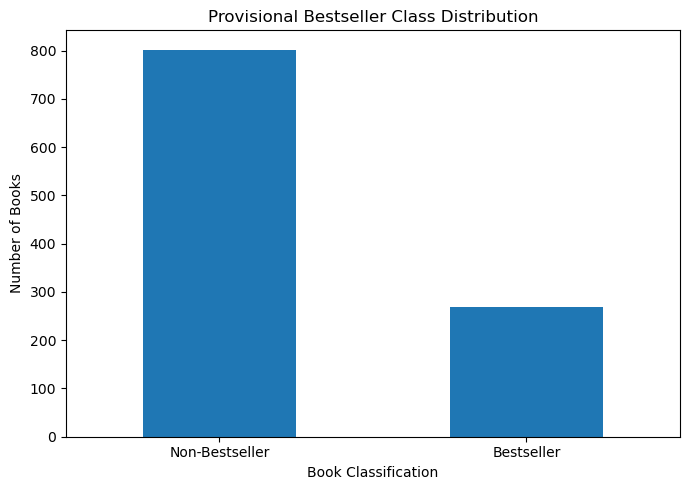

In [17]:
# Visualise the provisional binary target

target_summary.set_index("Class")["Count"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Provisional Bestseller Class Distribution")
plt.xlabel("Book Classification")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 1.15 Dataset Suitability Decision

Following the preliminary audit, the dataset was considered suitable for the proposed binary Logistic Regression analysis.

The dataset contains 1,070 book records and provides a combination of numerical and categorical characteristics that can be examined as potential predictors of commercial performance. No completely duplicated observations were identified, and the variables required to construct the target contain no missing values.

A small amount of missing metadata was identified in `Book Name`, `language_code` and `Publishing Year`. These issues are manageable because book titles are not intended to be used as predictive features, missing language values can be represented explicitly during categorical preparation, and only one publication year is missing.

The publication-year audit also identified books published before 1900, including several historical and ancient texts. These observations were retained because the values correspond to genuine publication periods rather than automatically representing data-entry errors.

Bestseller status is operationally defined as membership in the highest-selling 25% of books according to `units sold`. This produces a meaningful binary classification problem while retaining sufficient observations in both classes.

Variables that directly describe realised sales performance will not be used as predictors because doing so would introduce target leakage.

### 1.16 Analysis Plan

The analysis will follow a structured workflow informed by the preliminary dataset audit.

| Stage | Planned approach |
|---|---|
| **Exploratory Data Analysis** | Assess target balance, numerical distributions, categorical distributions, outliers, missing values and relationships between candidate predictors and bestseller status. |
| **Feature Selection** | Remove identifiers, high-cardinality variables and variables that create target or temporal leakage. Univariate statistical association tests will support feature screening, followed by validation-based comparison of full and reduced predictor sets. |
| **Data Preparation** | Split the data into stratified training, validation and test partitions. Missing numerical values will be imputed using training data only. Numerical predictors will be standardised and categorical predictors one-hot encoded. |
| **Model Training** | Implement Logistic Regression manually using NumPy, including the sigmoid function, binary cross-entropy loss, gradient calculation and gradient-descent optimisation. |
| **Hyperparameters** | Begin with a defined learning rate, maximum number of iterations and probability threshold, then adjust these only when validation evidence justifies retraining. |
| **Model Evaluation** | Evaluate accuracy, precision, recall, F1-score, confusion matrix, ROC curve and ROC-AUC. Class imbalance will be considered when interpreting results. |
| **Model Improvement** | Compare alternative feature sets, optimisation settings and classification thresholds using validation data without using the final test set for model selection. |
| **Final Report** | Document dataset quality, EDA findings, preprocessing, feature selection, from-scratch model development, model improvement, final test performance, limitations and business interpretation. |

## 2. Data Cleaning and Target Preparation

A separate working copy of the raw dataset is created so that the original imported data remains unchanged. Cleaning decisions are applied only where supported by the preceding data-quality audit.

In [18]:
# ---------------------------------------------------------
# 17. CREATE CLEAN WORKING COPY
# ---------------------------------------------------------

clean_df = books_df.copy()

print("Working copy created successfully.")
print(f"Original dataset shape: {books_df.shape}")
print(f"Working dataset shape: {clean_df.shape}")

Working copy created successfully.
Original dataset shape: (1070, 15)
Working dataset shape: (1070, 15)


### 2.1 Remove Non-Predictive Index Variable

The `index` variable was found to reproduce the sequential row position from 0 to 1,069. It therefore acts only as an identifier and contains no meaningful information about book characteristics or bestseller performance. The variable is removed from the working dataset.

In [19]:
# ---------------------------------------------------------
# 18. REMOVE ARTIFICIAL INDEX VARIABLE
# ---------------------------------------------------------

clean_df = clean_df.drop(columns=["index"])

print("Index column removed.")
print(f"Remaining columns: {clean_df.shape[1]}")

Index column removed.
Remaining columns: 14


### 2.2 Repeated Book-Title Investigation

Although no completely duplicated observations were identified, book titles are checked separately to determine whether the same title appears more than once. Repeated titles are not automatically removed because different editions or records may legitimately share a title.

In [20]:
# ---------------------------------------------------------
# 19. INSPECT REPEATED NON-MISSING BOOK TITLES
# ---------------------------------------------------------

duplicate_title_mask = (
    clean_df["Book Name"].notna() &
    clean_df["Book Name"].duplicated(keep=False)
)

duplicate_titles = clean_df.loc[
    duplicate_title_mask,
    [
        "Book Name",
        "Author",
        "Publishing Year",
        "language_code",
        "Publisher",
        "sale price",
        "units sold"
    ]
].sort_values("Book Name")

print(f"Records involving repeated book titles: {len(duplicate_titles)}")

display(duplicate_titles)

Records involving repeated book titles: 4


,Book Name,Author,Publishing Year,language_code,Publisher,sale price,units sold
297,Persepolis,"Marjane Satrapi, Mattias Ripa",2000.0,eng,Random House LLC,4.99,298
933,Persepolis,"Marjane Satrapi, Mattias Ripa, Blake Ferris, A...",2003.0,en-US,"Amazon Digital Services, Inc.",0.99,4320
251,The Awakening,Kate Chopin,1899.0,eng,"Amazon Digital Services, Inc.",0.99,375
696,The Awakening,Kelley Armstrong,2009.0,eng,Simon and Schuster Digital Sales Inc,6.45,36072


**Repeated-title decision:**  
Four records were associated with repeated book titles. Inspection showed that these records represented either different editions/commercial records or different books sharing the same title. Because the observations differed in authorship, publication information, pricing or sales performance, they were retained rather than treated as duplicate records.

### 2.3 Standardise Genre Labels

The categorical audit identified two labels representing the broad fiction category: `genre fiction` and `fiction`. These labels are consolidated to prevent the model from treating a naming inconsistency as two separate book genres.

In [21]:
# ---------------------------------------------------------
# 20. STANDARDISE GENRE LABELS
# ---------------------------------------------------------

clean_df["genre"] = clean_df["genre"].replace({
    "genre fiction": "fiction"
})

print("GENRE DISTRIBUTION AFTER STANDARDISATION")
print("-" * 60)

genre_summary = pd.DataFrame({
    "Count": clean_df["genre"].value_counts(),
    "Percentage": (
        clean_df["genre"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )
})

display(genre_summary)

GENRE DISTRIBUTION AFTER STANDARDISATION
------------------------------------------------------------


,Count,Percentage
genre,,
fiction,884,82.62
nonfiction,171,15.98
children,15,1.40


### 2.4 Standardise Publisher Labels

The publisher audit identified two closely related HarperCollins labels. These are consolidated to avoid introducing an artificial categorical distinction caused by inconsistent naming.

In [22]:
# ---------------------------------------------------------
# 21. STANDARDISE PUBLISHER LABELS
# ---------------------------------------------------------

clean_df["Publisher"] = clean_df["Publisher"].replace({
    "HarperCollins Publishing": "HarperCollins Publishers"
})

print("PUBLISHER DISTRIBUTION AFTER STANDARDISATION")
print("-" * 60)

display(
    clean_df["Publisher"]
    .value_counts()
    .to_frame(name="Count")
)

PUBLISHER DISTRIBUTION AFTER STANDARDISATION
------------------------------------------------------------


,Count
Publisher,
"Amazon Digital Services, Inc.",600
Random House LLC,120
Penguin Group (USA) LLC,108
HarperCollins Publishers,75
Hachette Book Group,66
Simon and Schuster Digital Sales Inc,56
Macmillan,41
HarperCollins Christian Publishing,4


### 2.5 Standardise Language Categories

Several language codes represent regional forms of English, including `eng`, `en-US`, `en-GB` and `en-CA`. These are consolidated into a single `English` category.

The remaining explicitly identified languages contain very few observations and are grouped as `Other`, while missing language information is retained as an explicit `Unknown` category rather than deleting otherwise complete book records.

In [23]:
# ---------------------------------------------------------
# 22. STANDARDISE LANGUAGE CATEGORIES
# ---------------------------------------------------------

english_codes = ["eng", "en-US", "en-GB", "en-CA"]

clean_df["language_group"] = np.where(
    clean_df["language_code"].isna(),
    "Unknown",
    np.where(
        clean_df["language_code"].isin(english_codes),
        "English",
        "Other"
    )
)

language_summary = pd.DataFrame({
    "Count": clean_df["language_group"].value_counts(),
    "Percentage": (
        clean_df["language_group"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )
})

print("STANDARDISED LANGUAGE DISTRIBUTION")
print("-" * 60)

display(language_summary)

STANDARDISED LANGUAGE DISTRIBUTION
------------------------------------------------------------


,Count,Percentage
language_group,,
English,1008,94.21
Unknown,53,4.95
Other,9,0.84


### 2.6 Define the Binary Bestseller Target

The source dataset does not provide an explicit binary bestseller label. Bestseller status is therefore operationally defined using observed unit sales.

The 75th percentile of `units sold` is used as the threshold. Books selling more than this value are assigned `Bestseller = 1`, while all remaining books are assigned `Bestseller = 0`.

This definition identifies the highest-selling quarter of books while retaining sufficient observations in both classes for model training and evaluation.

In [24]:
# ---------------------------------------------------------
# 23. CREATE BINARY BESTSELLER TARGET
# ---------------------------------------------------------

BESTSELLER_THRESHOLD = clean_df["units sold"].quantile(0.75)

clean_df["Bestseller"] = (
    clean_df["units sold"] > BESTSELLER_THRESHOLD
).astype(int)

print("BESTSELLER TARGET CREATED")
print("-" * 60)

print(
    f"Threshold: units sold > {BESTSELLER_THRESHOLD:,.2f}"
)

target_summary = pd.DataFrame({
    "Count": clean_df["Bestseller"].value_counts().sort_index(),
    "Percentage": (
        clean_df["Bestseller"]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
    )
})

target_summary.index = [
    "0 - Non-Bestseller",
    "1 - Bestseller"
]

display(target_summary)

BESTSELLER TARGET CREATED
------------------------------------------------------------
Threshold: units sold > 5,312.25


,Count,Percentage
0 - Non-Bestseller,802,74.95
1 - Bestseller,268,25.05


## 3. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is conducted to understand the characteristics of the cleaned dataset and determine how the available variables relate to bestseller status.

The analysis focuses on:

- the distribution of the binary target;
- numerical feature distributions and possible outliers;
- relationships between numerical predictors and bestseller status;
- differences in bestseller rates across categorical variables; and
- potential relationships between predictors that may affect Logistic Regression.

The findings from the EDA will be used to guide feature preparation, encoding, scaling and feature selection.

### 3.1 Cleaned Dataset Verification

The working dataset is checked after the initial cleaning and target-preparation steps to confirm its dimensions, target distribution and remaining missing values.

In [25]:
# ---------------------------------------------------------
# 24. VERIFY CLEANED DATASET
# ---------------------------------------------------------

print("CLEANED DATASET VERIFICATION")
print("-" * 60)

print(f"Rows: {clean_df.shape[0]:,}")
print(f"Columns: {clean_df.shape[1]}")

print("\nRemaining missing values:")
remaining_missing = clean_df.isnull().sum()
print(remaining_missing[remaining_missing > 0])

print("\nBestseller class distribution:")
print(clean_df["Bestseller"].value_counts().sort_index())

print("\nBestseller class percentages:")
print(
    clean_df["Bestseller"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

CLEANED DATASET VERIFICATION
------------------------------------------------------------
Rows: 1,070
Columns: 16

Remaining missing values:
Publishing Year     1
Book Name          23
language_code      53
dtype: int64

Bestseller class distribution:
Bestseller
0    802
1    268
Name: count, dtype: int64

Bestseller class percentages:
Bestseller
0    74.95
1    25.05
Name: proportion, dtype: float64


### 3.2 Bestseller Target Distribution

The distribution of the binary target is examined because class imbalance can affect both model training and the interpretation of evaluation metrics. A strongly imbalanced target would make accuracy alone an unreliable measure of model performance.

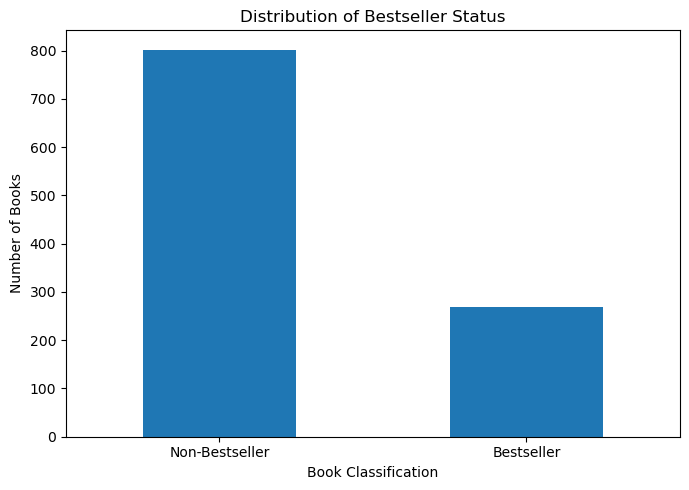

In [26]:
# ---------------------------------------------------------
# 25. VISUALISE BESTSELLER CLASS DISTRIBUTION
# ---------------------------------------------------------

target_plot = (
    clean_df["Bestseller"]
    .value_counts()
    .sort_index()
)

target_plot.index = ["Non-Bestseller", "Bestseller"]

target_plot.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Distribution of Bestseller Status")
plt.xlabel("Book Classification")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [27]:
# ---------------------------------------------------------
# 26. CALCULATE TARGET IMBALANCE RATIO
# ---------------------------------------------------------

class_counts = clean_df["Bestseller"].value_counts()

majority_count = class_counts.max()
minority_count = class_counts.min()

imbalance_ratio = majority_count / minority_count

print("TARGET BALANCE")
print("-" * 60)

print(f"Non-Bestsellers: {class_counts.get(0, 0):,}")
print(f"Bestsellers: {class_counts.get(1, 0):,}")
print(f"Majority-to-minority ratio: {imbalance_ratio:.2f}:1")

TARGET BALANCE
------------------------------------------------------------
Non-Bestsellers: 802
Bestsellers: 268
Majority-to-minority ratio: 2.99:1


### 3.3 Candidate Predictor Definition

Variables are separated according to whether they can reasonably be available when estimating bestseller potential.

Book identifiers and very high-cardinality fields are excluded from the candidate predictor set. Variables that directly represent realised sales performance are also excluded because they would leak information about the target.

Reader-response variables are excluded from the initial predictor set because they are generated after readers have interacted with the book and may therefore not be available when making an early commercial prediction.

In [28]:
# ---------------------------------------------------------
# 27. DEFINE VARIABLE ROLES
# ---------------------------------------------------------

identifier_variables = [
    "Book Name",
    "Author"
]

sales_leakage_variables = [
    "units sold",
    "gross sales",
    "publisher revenue",
    "sales rank"
]

post_outcome_variables = [
    "Book_average_rating",
    "Book_ratings_count"
]

candidate_predictors = [
    "Publishing Year",
    "Author_Rating",
    "genre",
    "sale price",
    "Publisher",
    "language_group"
]

target_variable = "Bestseller"

print("CANDIDATE PREDICTORS")
print("-" * 60)

for variable in candidate_predictors:
    print(f"- {variable}")

print("\nTARGET")
print("-" * 60)
print(target_variable)

CANDIDATE PREDICTORS
------------------------------------------------------------
- Publishing Year
- Author_Rating
- genre
- sale price
- Publisher
- language_group

TARGET
------------------------------------------------------------
Bestseller


### 3.4 Numerical Predictor Distributions

The numerical candidate predictors are examined to identify their distributions, ranges and potential outliers. This is particularly important for a Logistic Regression model trained using gradient descent because large differences in feature scale can affect optimisation.

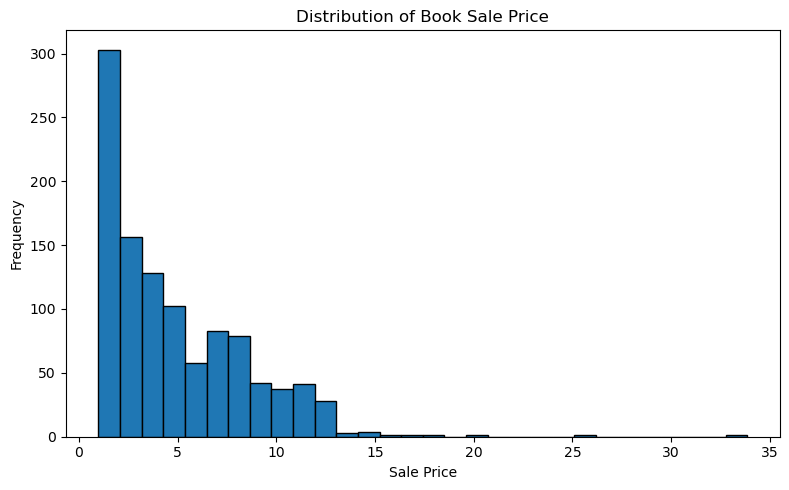

count    1070.000000
mean        4.869561
std         3.559919
min         0.990000
25%         1.990000
50%         3.990000
75%         6.990000
max        33.860000
Name: sale price, dtype: float64


In [29]:
# ---------------------------------------------------------
# 28. SALE PRICE DISTRIBUTION
# ---------------------------------------------------------

clean_df["sale price"].plot(
    kind="hist",
    bins=30,
    figsize=(8, 5),
    edgecolor="black"
)

plt.title("Distribution of Book Sale Price")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print(clean_df["sale price"].describe())

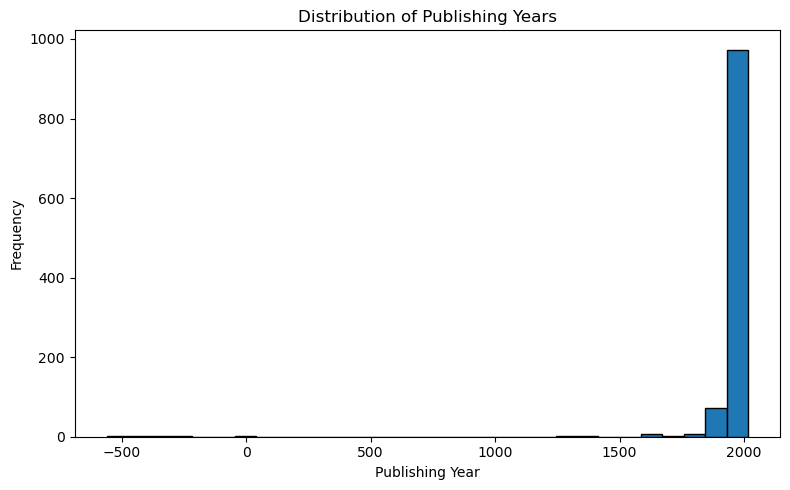

count    1069.000000
mean     1971.377923
std       185.080257
min      -560.000000
25%      1985.000000
50%      2003.000000
75%      2010.000000
max      2016.000000
Name: Publishing Year, dtype: float64


In [30]:
# ---------------------------------------------------------
# 29. PUBLISHING YEAR DISTRIBUTION
# ---------------------------------------------------------

valid_years = clean_df["Publishing Year"].dropna()

valid_years.plot(
    kind="hist",
    bins=30,
    figsize=(8, 5),
    edgecolor="black"
)

plt.title("Distribution of Publishing Years")
plt.xlabel("Publishing Year")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print(valid_years.describe())

### 3.5 Numerical Predictors and Bestseller Status

Numerical predictors are compared across the two target classes to determine whether their distributions show meaningful differences that may assist classification.

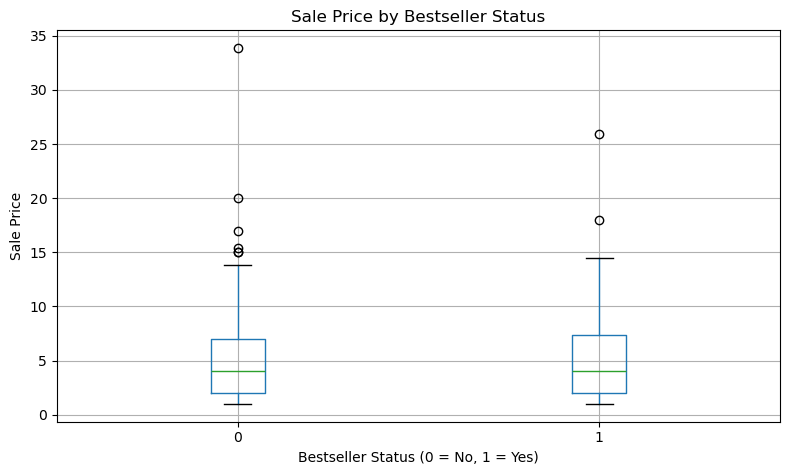

,count,mean,median,std,min,max
Bestseller,,,,,,
0,802,4.81,3.99,3.55,0.99,33.86
1,268,5.04,3.99,3.60,0.99,25.89


In [31]:
# ---------------------------------------------------------
# 30. SALE PRICE BY BESTSELLER STATUS
# ---------------------------------------------------------

clean_df.boxplot(
    column="sale price",
    by="Bestseller",
    figsize=(8, 5)
)

plt.title("Sale Price by Bestseller Status")
plt.suptitle("")
plt.xlabel("Bestseller Status (0 = No, 1 = Yes)")
plt.ylabel("Sale Price")
plt.tight_layout()
plt.show()

display(
    clean_df.groupby("Bestseller")["sale price"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

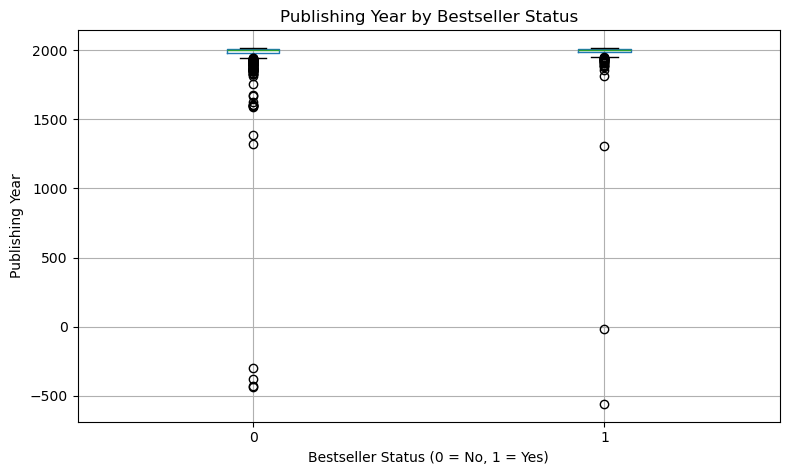

,count,mean,median,std,min,max
Bestseller,,,,,,
0,801,1970.91,2002.0,178.32,-441.0,2016.0
1,268,1972.77,2003.0,204.30,-560.0,2016.0


In [32]:
# ---------------------------------------------------------
# 31. PUBLISHING YEAR BY BESTSELLER STATUS
# ---------------------------------------------------------

clean_df.boxplot(
    column="Publishing Year",
    by="Bestseller",
    figsize=(8, 5)
)

plt.title("Publishing Year by Bestseller Status")
plt.suptitle("")
plt.xlabel("Bestseller Status (0 = No, 1 = Yes)")
plt.ylabel("Publishing Year")
plt.tight_layout()
plt.show()

display(
    clean_df.groupby("Bestseller")["Publishing Year"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

### 3.6 Author Rating and Bestseller Status

The bestseller rate is examined across author-rating categories to determine whether books associated with differently rated authors show different levels of commercial success.

In [33]:
# ---------------------------------------------------------
# 32. BESTSELLER RATE BY AUTHOR RATING
# ---------------------------------------------------------

author_rating_summary = (
    clean_df.groupby("Author_Rating")["Bestseller"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Books",
        "sum": "Bestsellers",
        "mean": "Bestseller Rate"
    })
)

author_rating_summary["Bestseller Rate"] = (
    author_rating_summary["Bestseller Rate"] * 100
).round(2)

display(
    author_rating_summary.sort_values(
        "Bestseller Rate",
        ascending=False
    )
)

,Books,Bestsellers,Bestseller Rate
Author_Rating,,,
Excellent,362,126,34.81
Novice,30,9,30.00
Intermediate,625,125,20.00
Famous,53,8,15.09


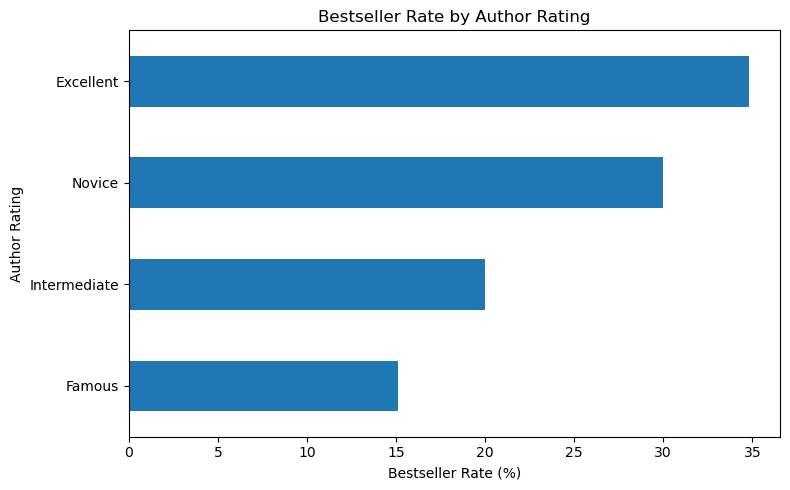

In [34]:
author_rating_summary["Bestseller Rate"].sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Bestseller Rate by Author Rating")
plt.xlabel("Bestseller Rate (%)")
plt.ylabel("Author Rating")
plt.tight_layout()
plt.show()

### 3.7 Genre and Bestseller Status

Genre is examined to determine whether bestseller proportions differ across fiction, nonfiction and children's books. These differences may indicate whether genre contributes useful classification information.

In [35]:
# ---------------------------------------------------------
# 33. BESTSELLER RATE BY GENRE
# ---------------------------------------------------------

genre_bestseller_summary = (
    clean_df.groupby("genre")["Bestseller"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Books",
        "sum": "Bestsellers",
        "mean": "Bestseller Rate"
    })
)

genre_bestseller_summary["Bestseller Rate"] = (
    genre_bestseller_summary["Bestseller Rate"] * 100
).round(2)

display(
    genre_bestseller_summary.sort_values(
        "Bestseller Rate",
        ascending=False
    )
)

,Books,Bestsellers,Bestseller Rate
genre,,,
children,15,7,46.67
nonfiction,171,46,26.90
fiction,884,215,24.32


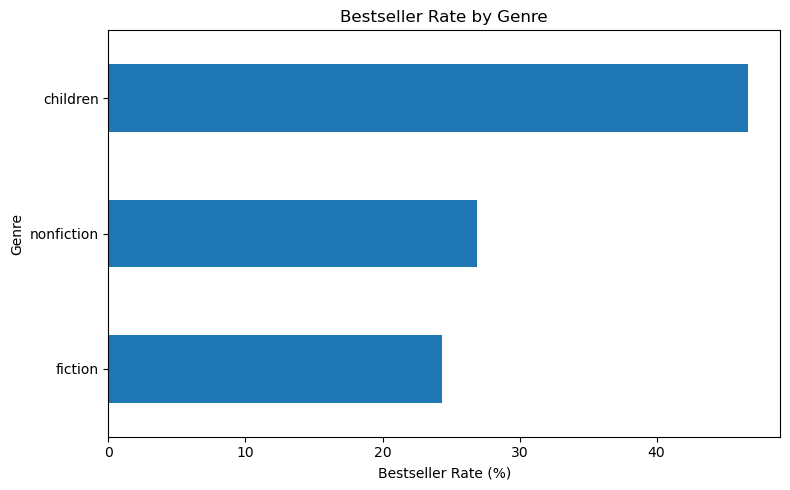

In [36]:
genre_bestseller_summary["Bestseller Rate"].sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Bestseller Rate by Genre")
plt.xlabel("Bestseller Rate (%)")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

### 3.8 Language Group and Bestseller Status

The simplified language categories are compared with bestseller status to determine whether language grouping contributes useful predictive information while avoiding unstable categories with very few observations.

In [37]:
# ---------------------------------------------------------
# 34. BESTSELLER RATE BY LANGUAGE GROUP
# ---------------------------------------------------------

language_bestseller_summary = (
    clean_df.groupby("language_group")["Bestseller"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Books",
        "sum": "Bestsellers",
        "mean": "Bestseller Rate"
    })
)

language_bestseller_summary["Bestseller Rate"] = (
    language_bestseller_summary["Bestseller Rate"] * 100
).round(2)

display(
    language_bestseller_summary.sort_values(
        "Bestseller Rate",
        ascending=False
    )
)

,Books,Bestsellers,Bestseller Rate
language_group,,,
English,1008,257,25.50
Unknown,53,10,18.87
Other,9,1,11.11


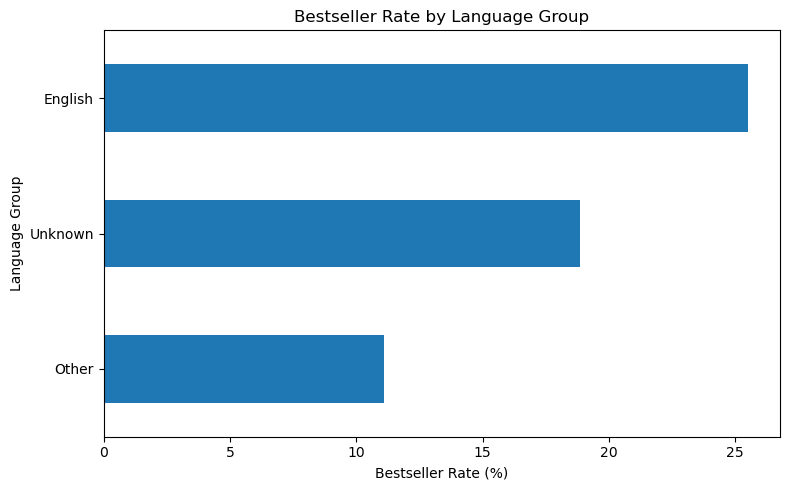

In [38]:
language_bestseller_summary["Bestseller Rate"].sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Bestseller Rate by Language Group")
plt.xlabel("Bestseller Rate (%)")
plt.ylabel("Language Group")
plt.tight_layout()
plt.show()

### 3.9 Publisher and Bestseller Status

Publisher-level bestseller rates are examined to determine whether books released by different publishers show different commercial-success patterns. Both the rate and the number of books represented by each publisher are considered because percentages based on very small groups can be unstable.

In [39]:
# ---------------------------------------------------------
# 35. BESTSELLER RATE BY PUBLISHER
# ---------------------------------------------------------

publisher_bestseller_summary = (
    clean_df.groupby("Publisher")["Bestseller"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Books",
        "sum": "Bestsellers",
        "mean": "Bestseller Rate"
    })
)

publisher_bestseller_summary["Bestseller Rate"] = (
    publisher_bestseller_summary["Bestseller Rate"] * 100
).round(2)

display(
    publisher_bestseller_summary.sort_values(
        "Bestseller Rate",
        ascending=False
    )
)

,Books,Bestsellers,Bestseller Rate
Publisher,,,
Random House LLC,120,35,29.17
"Amazon Digital Services, Inc.",600,156,26.00
HarperCollins Christian Publishing,4,1,25.00
Simon and Schuster Digital Sales Inc,56,14,25.00
HarperCollins Publishers,75,18,24.00
Hachette Book Group,66,14,21.21
Penguin Group (USA) LLC,108,22,20.37
Macmillan,41,8,19.51


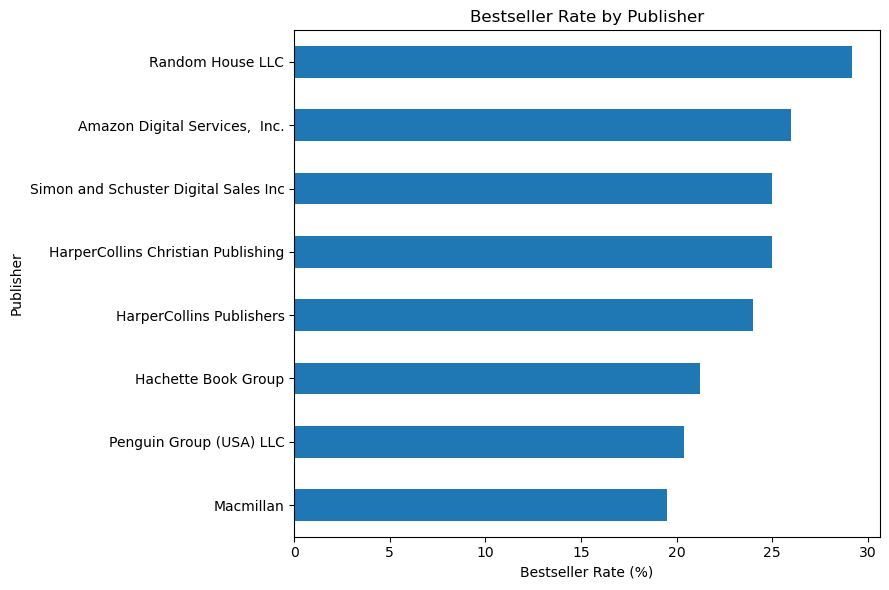

In [40]:
publisher_bestseller_summary["Bestseller Rate"].sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Bestseller Rate by Publisher")
plt.xlabel("Bestseller Rate (%)")
plt.ylabel("Publisher")
plt.tight_layout()
plt.show()

### 3.10 EDA Findings and Modelling Implications

The exploratory findings are used to guide subsequent feature preparation and selection rather than being treated as isolated descriptive results.

Sale price showed substantial overlap between bestseller and non-bestseller books, with both groups having a median price of 3.99. Publishing year also showed similar central tendencies between the two target classes, although the variable contains a wide historical range and will require scaling before gradient-based optimisation.

Author rating showed more noticeable differences in bestseller rates across categories, suggesting that author-related reputation may contain useful predictive information. Genre, language and publisher also showed some variation, although several categories contained relatively small numbers of observations and must therefore be interpreted cautiously.

These findings motivate formal statistical association tests before the final predictor set is selected.

### 3.11 Statistical Association Screening

Visual EDA is supplemented with statistical association tests to determine whether the candidate predictors show evidence of a relationship with bestseller status.

For categorical variables, Pearson's chi-square test is used to assess whether bestseller status is independent of the category, while Cramér's V is calculated to describe the strength of association.

For continuous numerical variables, both point-biserial correlation and the Mann–Whitney U test are examined. The latter does not require normally distributed predictors and is therefore useful given the skewness and historical outliers identified during EDA.

These tests are used as supporting evidence for feature selection rather than as the sole basis for retaining or removing variables.

In [41]:
# ---------------------------------------------------------
# 36. IMPORT STATISTICAL TESTS
# ---------------------------------------------------------

from scipy.stats import (
    chi2_contingency,
    pointbiserialr,
    mannwhitneyu
)

print("Statistical testing functions imported successfully.")

Statistical testing functions imported successfully.


In [42]:
# ---------------------------------------------------------
# 37. CHI-SQUARE TESTS FOR CATEGORICAL PREDICTORS
# ---------------------------------------------------------

categorical_predictors = [
    "Author_Rating",
    "genre",
    "language_group",
    "Publisher"
]

categorical_results = []

for variable in categorical_predictors:
    
    contingency_table = pd.crosstab(
        clean_df[variable],
        clean_df["Bestseller"]
    )
    
    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )
    
    n = contingency_table.to_numpy().sum()
    rows, columns = contingency_table.shape
    
    cramers_v = np.sqrt(
        (chi2 / n) /
        min(rows - 1, columns - 1)
    )
    
    categorical_results.append({
        "Variable": variable,
        "Chi-Square": chi2,
        "Degrees of Freedom": dof,
        "P-Value": p_value,
        "Cramer's V": cramers_v
    })

categorical_results_df = pd.DataFrame(
    categorical_results
)

display(
    categorical_results_df.round(4)
)

,Variable,Chi-Square,Degrees of Freedom,P-Value,Cramer's V
0,Author_Rating,30.0355,3,0.0000,0.1675
1,genre,4.2956,2,0.1167,0.0634
2,language_group,2.1172,2,0.3469,0.0445
3,Publisher,3.8632,7,0.7954,0.0601


In [43]:
# ---------------------------------------------------------
# 38. NUMERICAL ASSOCIATION TESTS
# ---------------------------------------------------------

numerical_predictors = [
    "Publishing Year",
    "sale price"
]

numerical_results = []

for variable in numerical_predictors:
    
    analysis_data = clean_df[
        [variable, "Bestseller"]
    ].dropna()
    
    # Point-biserial correlation
    correlation, correlation_p = pointbiserialr(
        analysis_data["Bestseller"],
        analysis_data[variable]
    )
    
    # Separate target groups for Mann-Whitney U
    non_bestsellers = analysis_data.loc[
        analysis_data["Bestseller"] == 0,
        variable
    ]
    
    bestsellers = analysis_data.loc[
        analysis_data["Bestseller"] == 1,
        variable
    ]
    
    u_statistic, mw_p = mannwhitneyu(
        non_bestsellers,
        bestsellers,
        alternative="two-sided"
    )
    
    numerical_results.append({
        "Variable": variable,
        "Point-Biserial r": correlation,
        "Correlation P-Value": correlation_p,
        "Mann-Whitney U": u_statistic,
        "Mann-Whitney P-Value": mw_p
    })

numerical_results_df = pd.DataFrame(
    numerical_results
)

display(
    numerical_results_df.round(4)
)

,Variable,Point-Biserial r,Correlation P-Value,Mann-Whitney U,Mann-Whitney P-Value
0,Publishing Year,0.0044,0.8868,104303.0,0.4883
1,sale price,0.0274,0.3703,103220.5,0.3289


In [44]:
# ---------------------------------------------------------
# 39. CHECK CHI-SQUARE EXPECTED FREQUENCIES
# ---------------------------------------------------------

print("CHI-SQUARE EXPECTED-FREQUENCY CHECK")
print("-" * 70)

for variable in categorical_predictors:
    
    contingency_table = pd.crosstab(
        clean_df[variable],
        clean_df["Bestseller"]
    )
    
    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )
    
    expected_df = pd.DataFrame(
        expected,
        index=contingency_table.index,
        columns=contingency_table.columns
    )
    
    cells_below_5 = (expected_df < 5).sum().sum()
    total_cells = expected_df.size
    
    print(
        f"{variable:<20} "
        f"Cells with expected frequency < 5: "
        f"{cells_below_5}/{total_cells}"
    )

CHI-SQUARE EXPECTED-FREQUENCY CHECK
----------------------------------------------------------------------
Author_Rating        Cells with expected frequency < 5: 0/8
genre                Cells with expected frequency < 5: 1/6
language_group       Cells with expected frequency < 5: 1/6
Publisher            Cells with expected frequency < 5: 2/16


**Chi-square assumption consideration:**  
The expected-frequency check showed that `Author_Rating` had no expected cell frequencies below 5, supporting the reliability of its chi-square result. In contrast, `genre`, `language_group` and `Publisher` contained a small number of cells with expected frequencies below 5. Their chi-square results are therefore interpreted cautiously, particularly for categories represented by relatively few books. These tests are used as supporting evidence for feature screening rather than as the sole basis for feature-selection decisions.

### 3.12 Missing Publishing-Year Observation

Only one observation lacks a publishing year. The record is inspected before selecting an imputation strategy because removing an otherwise valid book may unnecessarily reduce the modelling dataset.

In [45]:
# ---------------------------------------------------------
# 40. INSPECT MISSING PUBLISHING YEAR
# ---------------------------------------------------------

missing_year_record = clean_df[
    clean_df["Publishing Year"].isna()
]

display(
    missing_year_record[
        [
            "Book Name",
            "Author",
            "Author_Rating",
            "genre",
            "Publisher",
            "sale price",
            "units sold",
            "Bestseller"
        ]
    ]
)

,Book Name,Author,Author_Rating,genre,Publisher,sale price,units sold,Bestseller
445,NaN,"Robert Kapilow, Dr. Seuss",Famous,nonfiction,Hachette Book Group,2.99,4806,0


## 4. Feature Preparation and Selection

The feature-preparation stage converts the cleaned dataset into a modelling-ready representation while maintaining strict separation between training, validation and test information.

Feature selection begins with business and methodological considerations. Variables that act as identifiers, reveal realised sales performance or contain information generated after publication are excluded before statistical modelling.

The remaining candidate predictors are retained initially even where univariate association tests were not statistically significant. This is because univariate tests assess predictors independently and may not capture relationships that emerge when variables are considered jointly. Their contribution will therefore be reassessed using validation performance after the baseline Logistic Regression model has been trained.

In [46]:
# ---------------------------------------------------------
# 41. DEFINE FINAL CANDIDATE PREDICTORS AND TARGET
# ---------------------------------------------------------

final_candidate_predictors = [
    "Publishing Year",
    "sale price",
    "Author_Rating",
    "genre",
    "Publisher",
    "language_group"
]

target_variable = "Bestseller"

X = clean_df[final_candidate_predictors].copy()
y = clean_df[target_variable].copy()

print("MODELLING DATA")
print("-" * 60)
print(f"Predictor matrix shape: {X.shape}")
print(f"Target vector shape: {y.shape}")

print("\nCandidate predictors:")
for feature in final_candidate_predictors:
    print(f"- {feature}")

print("\nTarget:")
print(f"- {target_variable}")

MODELLING DATA
------------------------------------------------------------
Predictor matrix shape: (1070, 6)
Target vector shape: (1070,)

Candidate predictors:
- Publishing Year
- sale price
- Author_Rating
- genre
- Publisher
- language_group

Target:
- Bestseller


### 4.1 Stratified Training, Validation and Test Partitioning

The modelling dataset is divided into separate training, validation and test partitions.

A 70:15:15 strategy is used. The training partition is used to estimate model parameters, the validation partition is used for feature-selection and hyperparameter decisions, and the test partition is kept untouched until the final model has been selected.

Stratification is applied so that the proportion of bestseller and non-bestseller observations remains approximately consistent across all three partitions.

In [47]:
# ---------------------------------------------------------
# 42. CREATE STRATIFIED TRAIN / VALIDATION / TEST SPLITS
# ---------------------------------------------------------

from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: divide temporary data equally
# 15% validation and 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("DATA PARTITION SIZES")
print("-" * 60)

print(f"Training:   {len(X_train):,}")
print(f"Validation: {len(X_val):,}")
print(f"Test:       {len(X_test):,}")

print(f"\nTotal:      {len(X_train) + len(X_val) + len(X_test):,}")

DATA PARTITION SIZES
------------------------------------------------------------
Training:   749
Validation: 160
Test:       161

Total:      1,070


In [48]:
# ---------------------------------------------------------
# 43. VERIFY TARGET DISTRIBUTION ACROSS PARTITIONS
# ---------------------------------------------------------

def class_distribution(labels, partition_name):
    
    counts = labels.value_counts().sort_index()
    percentages = (
        labels.value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
    )
    
    return pd.DataFrame({
        "Partition": partition_name,
        "Class": ["Non-Bestseller", "Bestseller"],
        "Count": [
            counts.get(0, 0),
            counts.get(1, 0)
        ],
        "Percentage": [
            percentages.get(0, 0),
            percentages.get(1, 0)
        ]
    })


partition_distribution = pd.concat([
    class_distribution(y_train, "Training"),
    class_distribution(y_val, "Validation"),
    class_distribution(y_test, "Test")
], ignore_index=True)

display(partition_distribution)

,Partition,Class,Count,Percentage
0,Training,Non-Bestseller,561,74.90
1,Training,Bestseller,188,25.10
2,Validation,Non-Bestseller,120,75.00
3,Validation,Bestseller,40,25.00
4,Test,Non-Bestseller,121,75.16
5,Test,Bestseller,40,24.84


### 4.2 Numerical and Categorical Feature Groups

The selected predictors require different preprocessing methods. Numerical features will be median-imputed where necessary and standardised, while categorical variables will be converted into dummy variables using one-hot encoding.

In [49]:
# ---------------------------------------------------------
# 44. DEFINE NUMERICAL AND CATEGORICAL FEATURES
# ---------------------------------------------------------

numerical_features = [
    "Publishing Year",
    "sale price"
]

categorical_features = [
    "Author_Rating",
    "genre",
    "Publisher",
    "language_group"
]

print("NUMERICAL FEATURES")
print("-" * 60)

for feature in numerical_features:
    print(f"- {feature}")


print("\nCATEGORICAL FEATURES")
print("-" * 60)

for feature in categorical_features:
    print(f"- {feature}")

NUMERICAL FEATURES
------------------------------------------------------------
- Publishing Year
- sale price

CATEGORICAL FEATURES
------------------------------------------------------------
- Author_Rating
- genre
- Publisher
- language_group


### 4.3 Training-Only Preprocessing

Preprocessing parameters are learned from the training partition only. This prevents information from the validation and test partitions from influencing the model-development process.

The single missing publishing-year value is imputed using the training-set median. Numerical features are then standardised to approximately zero mean and unit variance. Standardisation is particularly important for the manually implemented gradient-descent algorithm because predictors measured on very different scales can result in inefficient optimisation.

Categorical predictors are one-hot encoded. One reference category is dropped from each feature to avoid redundant dummy variables.

In [50]:
# ---------------------------------------------------------
# 45. BUILD PREPROCESSING PIPELINE
# ---------------------------------------------------------

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


numerical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])


categorical_pipeline = Pipeline([
    (
        "encoder",
        OneHotEncoder(
            drop="first",
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])


preprocessor = ColumnTransformer([
    (
        "numerical",
        numerical_pipeline,
        numerical_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [51]:
# ---------------------------------------------------------
# 46. FIT PREPROCESSING ON TRAINING DATA ONLY
# ---------------------------------------------------------

X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("PREPROCESSED DATA DIMENSIONS")
print("-" * 60)

print(f"Training:   {X_train_processed.shape}")
print(f"Validation: {X_val_processed.shape}")
print(f"Test:       {X_test_processed.shape}")

PREPROCESSED DATA DIMENSIONS
------------------------------------------------------------
Training:   (749, 16)
Validation: (160, 16)
Test:       (161, 16)


In [52]:
# ---------------------------------------------------------
# 47. RETRIEVE PROCESSED FEATURE NAMES
# ---------------------------------------------------------

processed_feature_names = (
    preprocessor.get_feature_names_out()
)

processed_feature_names = [
    name
    .replace("numerical__", "")
    .replace("categorical__", "")
    for name in processed_feature_names
]

print("PROCESSED MODEL FEATURES")
print("-" * 60)

for i, feature in enumerate(
    processed_feature_names,
    start=1
):
    print(f"{i:>2}. {feature}")

print(
    f"\nTotal processed features: "
    f"{len(processed_feature_names)}"
)

PROCESSED MODEL FEATURES
------------------------------------------------------------
 1. Publishing Year
 2. sale price
 3. Author_Rating_Famous
 4. Author_Rating_Intermediate
 5. Author_Rating_Novice
 6. genre_fiction
 7. genre_nonfiction
 8. Publisher_Hachette Book Group
 9. Publisher_HarperCollins Christian Publishing
10. Publisher_HarperCollins Publishers
11. Publisher_Macmillan
12. Publisher_Penguin Group (USA) LLC
13. Publisher_Random House LLC
14. Publisher_Simon and Schuster Digital Sales Inc
15. language_group_Other
16. language_group_Unknown

Total processed features: 16


In [53]:
# ---------------------------------------------------------
# 48. VERIFY PREPROCESSED MATRICES
# ---------------------------------------------------------

print("PREPROCESSING VERIFICATION")
print("-" * 60)

print(
    "Missing values in training matrix:",
    np.isnan(X_train_processed).sum()
)

print(
    "Missing values in validation matrix:",
    np.isnan(X_val_processed).sum()
)

print(
    "Missing values in test matrix:",
    np.isnan(X_test_processed).sum()
)

print(
    "\nInfinite values in training matrix:",
    np.isinf(X_train_processed).sum()
)

print(
    "Infinite values in validation matrix:",
    np.isinf(X_val_processed).sum()
)

print(
    "Infinite values in test matrix:",
    np.isinf(X_test_processed).sum()
)

PREPROCESSING VERIFICATION
------------------------------------------------------------
Missing values in training matrix: 0
Missing values in validation matrix: 0
Missing values in test matrix: 0

Infinite values in training matrix: 0
Infinite values in validation matrix: 0
Infinite values in test matrix: 0


## 5. Logistic Regression From Scratch

The Logistic Regression classifier is implemented manually using NumPy rather than a pre-built classification estimator.

For each observation, the model first calculates a linear combination of the input features:

\[
z = Xw + b
\]

where:

- \(X\) represents the predictor matrix;
- \(w\) represents the model weights; and
- \(b\) represents the intercept.

The linear output is converted into a probability using the sigmoid function:

\[
\sigma(z) = \frac{1}{1 + e^{-z}}
\]

The resulting value lies between 0 and 1 and represents the estimated probability that a book belongs to the bestseller class.

Model parameters are learned by minimising binary cross-entropy loss using gradient descent. The gradient of the loss is calculated with respect to the weights and intercept, after which the parameters are updated iteratively.

The baseline model will initially use a classification threshold of 0.50. Model-development decisions will be based on validation performance, while the test set will remain untouched until the final model has been selected.

### 5.1 Prepare NumPy Matrices

The manually implemented Logistic Regression algorithm operates directly on NumPy arrays. The prepared training, validation and test predictors and target vectors are therefore converted into consistent numerical array formats.

In [54]:
# ---------------------------------------------------------
# 49. PREPARE NUMPY ARRAYS
# ---------------------------------------------------------

X_train_np = np.asarray(X_train_processed, dtype=float)
X_val_np = np.asarray(X_val_processed, dtype=float)
X_test_np = np.asarray(X_test_processed, dtype=float)

y_train_np = y_train.to_numpy(dtype=float)
y_val_np = y_val.to_numpy(dtype=float)
y_test_np = y_test.to_numpy(dtype=float)

print("NUMPY ARRAY DIMENSIONS")
print("-" * 60)

print(f"X_train: {X_train_np.shape}")
print(f"y_train: {y_train_np.shape}")

print(f"X_val:   {X_val_np.shape}")
print(f"y_val:   {y_val_np.shape}")

print(f"X_test:  {X_test_np.shape}")
print(f"y_test:  {y_test_np.shape}")

NUMPY ARRAY DIMENSIONS
------------------------------------------------------------
X_train: (749, 16)
y_train: (749,)
X_val:   (160, 16)
y_val:   (160,)
X_test:  (161, 16)
y_test:  (161,)


### 5.2 Sigmoid Function

The sigmoid function transforms the unrestricted linear model output into a probability between 0 and 1.

To improve numerical stability, extremely large positive or negative linear values are clipped before applying the exponential function.

In [55]:
# ---------------------------------------------------------
# 50. IMPLEMENT SIGMOID FUNCTION
# ---------------------------------------------------------

def sigmoid(z):
    """
    Convert linear model outputs into probabilities
    between 0 and 1.
    """
    
    z = np.clip(z, -500, 500)
    
    return 1 / (1 + np.exp(-z))

In [56]:
# Test the sigmoid function using sample values

test_values = np.array([-5, -1, 0, 1, 5], dtype=float)
test_probabilities = sigmoid(test_values)

sigmoid_test = pd.DataFrame({
    "Linear Value (z)": test_values,
    "Sigmoid Probability": test_probabilities
})

display(sigmoid_test.round(4))

,Linear Value (z),Sigmoid Probability
0,-5.0,0.0067
1,-1.0,0.2689
2,0.0,0.5000
3,1.0,0.7311
4,5.0,0.9933


### 5.3 Binary Cross-Entropy Loss

Binary cross-entropy measures the difference between the observed class labels and the probabilities predicted by the model.

For \(m\) observations, the loss is:

\[
J(w,b) =
-\frac{1}{m}
\sum_{i=1}^{m}
\left[
y_i\log(p_i) +
(1-y_i)\log(1-p_i)
\right]
\]

where \(y_i\) is the observed class and \(p_i\) is the predicted probability.

Lower loss values indicate better agreement between the predicted probabilities and the observed classes.

In [57]:
# ---------------------------------------------------------
# 51. IMPLEMENT BINARY CROSS-ENTROPY LOSS
# ---------------------------------------------------------

def binary_cross_entropy(y_true, y_probability):
    """
    Calculate mean binary cross-entropy loss.
    """
    
    epsilon = 1e-15
    
    y_probability = np.clip(
        y_probability,
        epsilon,
        1 - epsilon
    )
    
    loss = -np.mean(
        y_true * np.log(y_probability)
        +
        (1 - y_true) * np.log(1 - y_probability)
    )
    
    return loss

In [58]:
# Test the loss function with simple probabilities

example_y = np.array([1, 0, 1, 0])

good_predictions = np.array([
    0.90,
    0.10,
    0.85,
    0.15
])

poor_predictions = np.array([
    0.55,
    0.45,
    0.52,
    0.48
])

print("LOSS FUNCTION TEST")
print("-" * 60)

print(
    f"Loss for strong predictions: "
    f"{binary_cross_entropy(example_y, good_predictions):.4f}"
)

print(
    f"Loss for weak predictions:   "
    f"{binary_cross_entropy(example_y, poor_predictions):.4f}"
)

LOSS FUNCTION TEST
------------------------------------------------------------
Loss for strong predictions: 0.1339
Loss for weak predictions:   0.6259


### 5.4 Gradient Calculation

Gradient descent requires the derivative of the loss function with respect to each model parameter.

For the weight vector:

\[
\frac{\partial J}{\partial w}
=
\frac{1}{m}X^T(p-y)
\]

and for the intercept:

\[
\frac{\partial J}{\partial b}
=
\frac{1}{m}\sum(p-y)
\]

These gradients indicate the direction in which the parameters should be adjusted to reduce the loss.

In [59]:
# ---------------------------------------------------------
# 52. IMPLEMENT GRADIENT CALCULATION
# ---------------------------------------------------------

def compute_gradients(X, y, probabilities):
    """
    Calculate gradients for the weights and intercept.
    """
    
    m = X.shape[0]
    
    errors = probabilities - y
    
    dw = (1 / m) * (X.T @ errors)
    
    db = (1 / m) * np.sum(errors)
    
    return dw, db

### 5.5 Gradient-Descent Training Algorithm

Model parameters are initialised to zero and updated repeatedly using gradient descent.

At each iteration:

1. calculate the linear predictor \(z = Xw + b\);
2. convert \(z\) into probabilities using the sigmoid function;
3. calculate binary cross-entropy loss;
4. calculate the gradients;
5. update the weights and intercept.

The learning rate controls the size of each parameter update, while the number of iterations determines how many optimisation steps are performed.

Validation loss is recorded for monitoring purposes but is not used directly to calculate parameter updates.

In [60]:
# ---------------------------------------------------------
# 53. IMPLEMENT LOGISTIC REGRESSION TRAINING
# ---------------------------------------------------------

def train_logistic_regression(
    X_train,
    y_train,
    X_val=None,
    y_val=None,
    learning_rate=0.05,
    iterations=5000
):
    """
    Train Logistic Regression from scratch using
    batch gradient descent.
    """
    
    n_features = X_train.shape[1]
    
    # Initialise model parameters
    weights = np.zeros(n_features)
    bias = 0.0
    
    training_loss_history = []
    validation_loss_history = []
    
    for iteration in range(iterations):
        
        # ---------------------------------------------
        # Forward pass
        # ---------------------------------------------
        
        linear_output = (
            X_train @ weights + bias
        )
        
        train_probabilities = sigmoid(
            linear_output
        )
        
        # ---------------------------------------------
        # Calculate training loss
        # ---------------------------------------------
        
        train_loss = binary_cross_entropy(
            y_train,
            train_probabilities
        )
        
        training_loss_history.append(
            train_loss
        )
        
        # ---------------------------------------------
        # Calculate gradients
        # ---------------------------------------------
        
        dw, db = compute_gradients(
            X_train,
            y_train,
            train_probabilities
        )
        
        # ---------------------------------------------
        # Gradient-descent update
        # ---------------------------------------------
        
        weights -= learning_rate * dw
        bias -= learning_rate * db
        
        # ---------------------------------------------
        # Validation loss
        # ---------------------------------------------
        
        if X_val is not None and y_val is not None:
            
            val_probabilities = sigmoid(
                X_val @ weights + bias
            )
            
            val_loss = binary_cross_entropy(
                y_val,
                val_probabilities
            )
            
            validation_loss_history.append(
                val_loss
            )
    
    return {
        "weights": weights,
        "bias": bias,
        "training_loss": training_loss_history,
        "validation_loss": validation_loss_history
    }

### 5.6 Probability and Class Prediction

The trained weights and intercept are used to generate probabilities for new observations.

A probability threshold converts these probabilities into binary class predictions. The baseline model uses the conventional threshold of 0.50:

- probability below 0.50 → non-bestseller;
- probability of 0.50 or higher → bestseller.

In [61]:
# ---------------------------------------------------------
# 54. IMPLEMENT PREDICTION FUNCTIONS
# ---------------------------------------------------------

def predict_probability(X, weights, bias):
    """
    Return predicted probability of the positive class.
    """
    
    linear_output = X @ weights + bias
    
    return sigmoid(linear_output)


def predict_class(
    X,
    weights,
    bias,
    threshold=0.50
):
    """
    Convert predicted probabilities into binary classes.
    """
    
    probabilities = predict_probability(
        X,
        weights,
        bias
    )
    
    predictions = (
        probabilities >= threshold
    ).astype(int)
    
    return predictions

### 5.7 Baseline Training Configuration

The baseline Logistic Regression model uses a learning rate of 0.05 and 5,000 gradient-descent iterations.

Because the numerical variables were standardised during preprocessing, a moderate learning rate can be used without extremely large differences in predictor scale dominating the optimisation process.

The purpose of the baseline configuration is to establish an initial reference model. Changes to optimisation settings or the decision threshold will only be introduced later if validation results demonstrate a clear need for improvement.

In [62]:
# ---------------------------------------------------------
# 55. BASELINE MODEL CONFIGURATION
# ---------------------------------------------------------

BASELINE_LEARNING_RATE = 0.05
BASELINE_ITERATIONS = 5000
BASELINE_THRESHOLD = 0.50

baseline_configuration = pd.DataFrame({
    "Setting": [
        "Learning rate",
        "Iterations",
        "Classification threshold",
        "Optimisation method"
    ],
    "Value": [
        BASELINE_LEARNING_RATE,
        BASELINE_ITERATIONS,
        BASELINE_THRESHOLD,
        "Batch Gradient Descent"
    ]
})

display(baseline_configuration)

,Setting,Value
0,Learning rate,0.05
1,Iterations,5000
2,Classification threshold,0.5
3,Optimisation method,Batch Gradient Descent


In [63]:
# ---------------------------------------------------------
# 56. TRAIN BASELINE LOGISTIC REGRESSION MODEL
# ---------------------------------------------------------

baseline_model = train_logistic_regression(
    X_train=X_train_np,
    y_train=y_train_np,
    X_val=X_val_np,
    y_val=y_val_np,
    learning_rate=BASELINE_LEARNING_RATE,
    iterations=BASELINE_ITERATIONS
)

baseline_weights = baseline_model["weights"]
baseline_bias = baseline_model["bias"]

print("BASELINE TRAINING COMPLETED")
print("-" * 60)

print(
    f"Initial training loss: "
    f"{baseline_model['training_loss'][0]:.6f}"
)

print(
    f"Final training loss:   "
    f"{baseline_model['training_loss'][-1]:.6f}"
)

print(
    f"Final validation loss: "
    f"{baseline_model['validation_loss'][-1]:.6f}"
)

print(
    f"\nLearned intercept: "
    f"{baseline_bias:.6f}"
)

print(
    f"Number of learned weights: "
    f"{len(baseline_weights)}"
)

BASELINE TRAINING COMPLETED
------------------------------------------------------------
Initial training loss: 0.693147
Final training loss:   0.548574
Final validation loss: 0.558452

Learned intercept: -0.269940
Number of learned weights: 16


### 5.8 Baseline Training Behaviour

Training and validation loss are examined across optimisation iterations to confirm that gradient descent is converging and to identify possible signs of unstable learning or overfitting.

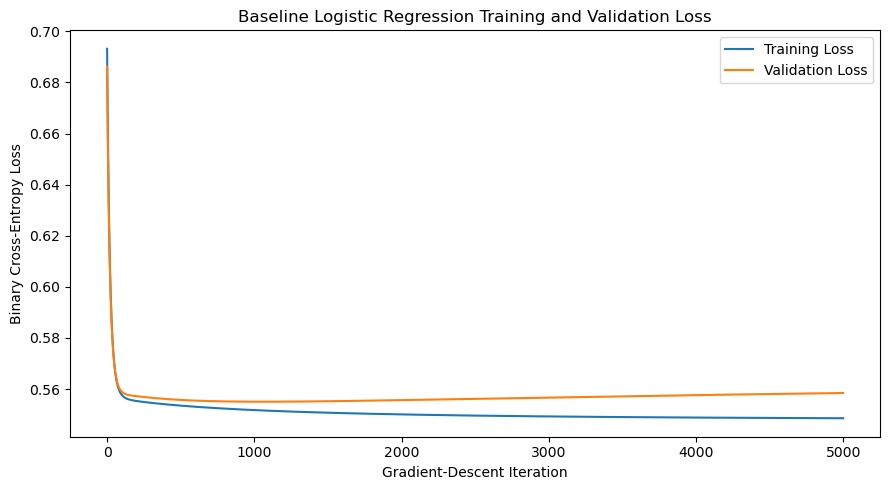

In [64]:
# ---------------------------------------------------------
# 57. PLOT TRAINING AND VALIDATION LOSS
# ---------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    baseline_model["training_loss"],
    label="Training Loss"
)

plt.plot(
    baseline_model["validation_loss"],
    label="Validation Loss"
)

plt.title(
    "Baseline Logistic Regression Training and Validation Loss"
)

plt.xlabel("Gradient-Descent Iteration")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [65]:
# ---------------------------------------------------------
# 58. GENERATE BASELINE VALIDATION PREDICTIONS
# ---------------------------------------------------------

baseline_val_probabilities = predict_probability(
    X_val_np,
    baseline_weights,
    baseline_bias
)

baseline_val_predictions = predict_class(
    X_val_np,
    baseline_weights,
    baseline_bias,
    threshold=BASELINE_THRESHOLD
)

print("VALIDATION PREDICTION SUMMARY")
print("-" * 60)

print(
    f"Predicted non-bestsellers: "
    f"{np.sum(baseline_val_predictions == 0)}"
)

print(
    f"Predicted bestsellers: "
    f"{np.sum(baseline_val_predictions == 1)}"
)

print(
    f"\nMinimum predicted probability: "
    f"{baseline_val_probabilities.min():.4f}"
)

print(
    f"Maximum predicted probability: "
    f"{baseline_val_probabilities.max():.4f}"
)

print(
    f"Mean predicted probability: "
    f"{baseline_val_probabilities.mean():.4f}"
)

VALIDATION PREDICTION SUMMARY
------------------------------------------------------------
Predicted non-bestsellers: 160
Predicted bestsellers: 0

Minimum predicted probability: 0.1317
Maximum predicted probability: 0.4338
Mean predicted probability: 0.2462


## 6. Baseline Model Evaluation

The baseline Logistic Regression model is evaluated using the validation partition. The validation set is used rather than the test set because model-development decisions, including threshold adjustment and feature refinement, must be made before final generalisation performance is assessed.

Because approximately 25% of books are classified as bestsellers, accuracy alone may provide a misleading view of performance. The model is therefore evaluated using:

- accuracy;
- balanced accuracy;
- precision;
- recall (sensitivity);
- specificity;
- F1-score;
- confusion matrix; and
- ROC-AUC.

These measures provide complementary information about the model's ability to identify both bestseller and non-bestseller books.

In [66]:
# ---------------------------------------------------------
# 59. IMPORT MODEL-EVALUATION METRICS
# ---------------------------------------------------------

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

print("Evaluation metrics imported successfully.")

Evaluation metrics imported successfully.


### 6.1 Evaluation Function

A reusable evaluation function is created so that every model experiment is assessed using the same performance measures.

Specificity is calculated directly from the confusion matrix and measures the proportion of actual non-bestsellers correctly identified by the model.

In [67]:
# ---------------------------------------------------------
# 60. CREATE BINARY CLASSIFICATION EVALUATION FUNCTION
# ---------------------------------------------------------

def evaluate_binary_classifier(
    y_true,
    y_pred,
    y_probability
):
    """
    Evaluate a binary classifier using multiple
    complementary performance measures.
    """
    
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()
    
    accuracy = accuracy_score(
        y_true,
        y_pred
    )
    
    balanced_accuracy = balanced_accuracy_score(
        y_true,
        y_pred
    )
    
    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )
    
    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )
    
    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )
    
    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )
    
    roc_auc = roc_auc_score(
        y_true,
        y_probability
    )
    
    metrics = pd.DataFrame({
        "Metric": [
            "Accuracy",
            "Balanced Accuracy",
            "Precision",
            "Recall",
            "Specificity",
            "F1-Score",
            "ROC-AUC"
        ],
        "Score": [
            accuracy,
            balanced_accuracy,
            precision,
            recall,
            specificity,
            f1,
            roc_auc
        ]
    })
    
    return metrics, {
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

### 6.2 Baseline Validation Performance

The baseline model is evaluated using the default probability threshold of 0.50. This establishes the reference performance against which later model improvements will be compared.

In [68]:
# ---------------------------------------------------------
# 61. EVALUATE BASELINE MODEL ON VALIDATION DATA
# ---------------------------------------------------------

baseline_validation_metrics, baseline_confusion = (
    evaluate_binary_classifier(
        y_val_np,
        baseline_val_predictions,
        baseline_val_probabilities
    )
)

print("BASELINE VALIDATION PERFORMANCE")
print("-" * 60)

display(
    baseline_validation_metrics.assign(
        Score=lambda x: x["Score"].round(4)
    )
)

print("\nCONFUSION MATRIX COUNTS")
print("-" * 60)

for key, value in baseline_confusion.items():
    print(f"{key}: {value}")

BASELINE VALIDATION PERFORMANCE
------------------------------------------------------------


,Metric,Score
0,Accuracy,0.7500
1,Balanced Accuracy,0.5000
2,Precision,0.0000
3,Recall,0.0000
4,Specificity,1.0000
5,F1-Score,0.0000
6,ROC-AUC,0.5724



CONFUSION MATRIX COUNTS
------------------------------------------------------------
TN: 120
FP: 0
FN: 40
TP: 0


### 6.3 Majority-Class Benchmark

A majority-class benchmark is used to provide context for the baseline model.

Since non-bestsellers form the majority class, the benchmark predicts every validation observation as a non-bestseller. A useful classification model should provide value beyond this naïve strategy, particularly in its ability to identify the minority bestseller class.

In [69]:
# ---------------------------------------------------------
# 62. CREATE MAJORITY-CLASS BENCHMARK
# ---------------------------------------------------------

majority_predictions = np.zeros(
    len(y_val_np),
    dtype=int
)

majority_accuracy = accuracy_score(
    y_val_np,
    majority_predictions
)

majority_balanced_accuracy = balanced_accuracy_score(
    y_val_np,
    majority_predictions
)

majority_precision = precision_score(
    y_val_np,
    majority_predictions,
    zero_division=0
)

majority_recall = recall_score(
    y_val_np,
    majority_predictions,
    zero_division=0
)

majority_f1 = f1_score(
    y_val_np,
    majority_predictions,
    zero_division=0
)

majority_benchmark = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Majority Benchmark": [
        majority_accuracy,
        majority_balanced_accuracy,
        majority_precision,
        majority_recall,
        majority_f1
    ]
})

display(
    majority_benchmark.round(4)
)

,Metric,Majority Benchmark
0,Accuracy,0.75
1,Balanced Accuracy,0.50
2,Precision,0.00
3,Recall,0.00
4,F1-Score,0.00


In [70]:
# ---------------------------------------------------------
# 63. COMPARE BASELINE WITH MAJORITY BENCHMARK
# ---------------------------------------------------------

baseline_lookup = (
    baseline_validation_metrics
    .set_index("Metric")["Score"]
)

benchmark_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Majority Benchmark": [
        majority_accuracy,
        majority_balanced_accuracy,
        majority_precision,
        majority_recall,
        majority_f1
    ],
    "Baseline Logistic Regression": [
        baseline_lookup["Accuracy"],
        baseline_lookup["Balanced Accuracy"],
        baseline_lookup["Precision"],
        baseline_lookup["Recall"],
        baseline_lookup["F1-Score"]
    ]
})

display(
    benchmark_comparison.round(4)
)

,Metric,Majority Benchmark,Baseline Logistic Regression
0,Accuracy,0.75,0.75
1,Balanced Accuracy,0.50,0.50
2,Precision,0.00,0.00
3,Recall,0.00,0.00
4,F1-Score,0.00,0.00


### 6.4 Baseline Confusion Matrix

The confusion matrix shows the number of correctly and incorrectly classified observations in each target class. It is particularly useful for identifying whether apparently acceptable accuracy is being achieved by ignoring the minority bestseller class.

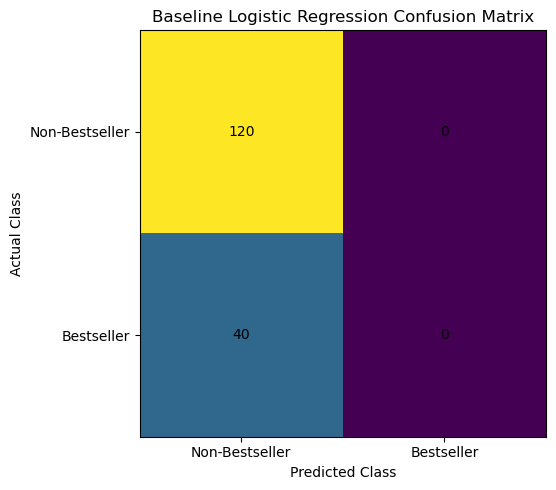

In [71]:
# ---------------------------------------------------------
# 64. PLOT BASELINE CONFUSION MATRIX
# ---------------------------------------------------------

baseline_cm = confusion_matrix(
    y_val_np,
    baseline_val_predictions,
    labels=[0, 1]
)

fig, ax = plt.subplots(
    figsize=(6, 5)
)

image = ax.imshow(
    baseline_cm
)

ax.set_title(
    "Baseline Logistic Regression Confusion Matrix"
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

ax.set_xticks([0, 1])
ax.set_xticklabels([
    "Non-Bestseller",
    "Bestseller"
])

ax.set_yticks([0, 1])
ax.set_yticklabels([
    "Non-Bestseller",
    "Bestseller"
])

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            baseline_cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

### 6.5 ROC-AUC and Threshold-Independent Performance

The Receiver Operating Characteristic (ROC) curve evaluates the model across different probability thresholds.

ROC-AUC is particularly useful for the baseline model because poor classification at a threshold of 0.50 does not necessarily mean that the predicted probabilities contain no useful ranking information. An ROC-AUC substantially above 0.50 would indicate that the model distinguishes bestsellers from non-bestsellers better than random ranking even if the default threshold is unsuitable.

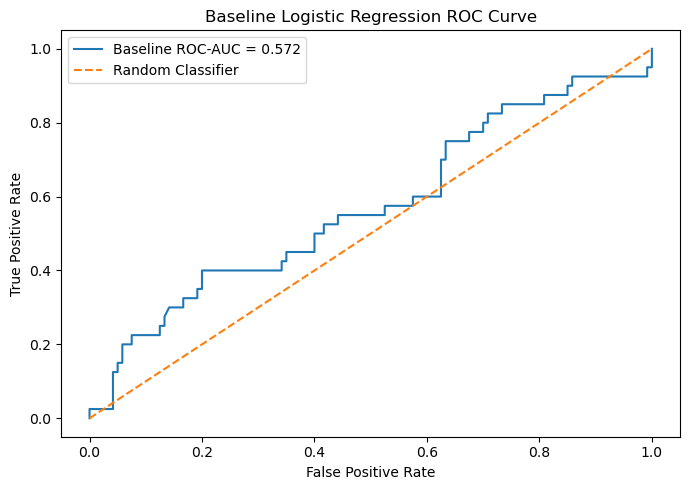

Baseline validation ROC-AUC: 0.5724


In [72]:
# ---------------------------------------------------------
# 65. CALCULATE AND PLOT BASELINE ROC CURVE
# ---------------------------------------------------------

fpr, tpr, roc_thresholds = roc_curve(
    y_val_np,
    baseline_val_probabilities
)

baseline_auc = roc_auc_score(
    y_val_np,
    baseline_val_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Baseline ROC-AUC = {baseline_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title(
    "Baseline Logistic Regression ROC Curve"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.tight_layout()
plt.show()

print(
    f"Baseline validation ROC-AUC: "
    f"{baseline_auc:.4f}"
)

### 6.6 Predicted Probability Distribution

The distribution of predicted bestseller probabilities is examined separately for actual bestsellers and non-bestsellers.

If actual bestsellers tend to receive higher probabilities than actual non-bestsellers, the model may contain useful discriminatory information even though none of its probabilities currently reach the default classification threshold of 0.50.

In [73]:
# ---------------------------------------------------------
# 66. COMPARE PROBABILITY DISTRIBUTIONS BY TRUE CLASS
# ---------------------------------------------------------

probability_analysis = pd.DataFrame({
    "Actual Class": y_val_np.astype(int),
    "Predicted Probability": baseline_val_probabilities
})

probability_summary = (
    probability_analysis
    .groupby("Actual Class")["Predicted Probability"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
)

probability_summary.index = [
    "Non-Bestseller",
    "Bestseller"
]

display(
    probability_summary.round(4)
)

,count,mean,median,std,min,max
Non-Bestseller,120,0.2424,0.2239,0.0559,0.1505,0.3889
Bestseller,40,0.2575,0.2486,0.0681,0.1317,0.4338


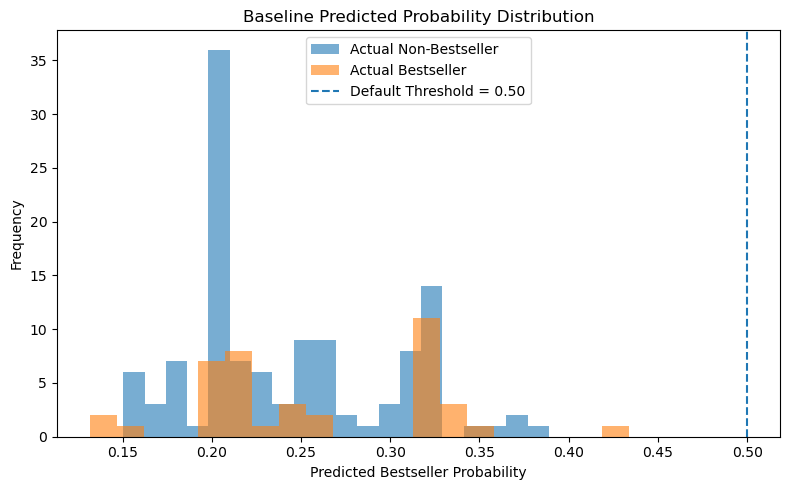

In [74]:
# ---------------------------------------------------------
# 67. VISUALISE VALIDATION PROBABILITY DISTRIBUTIONS
# ---------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.hist(
    baseline_val_probabilities[y_val_np == 0],
    bins=20,
    alpha=0.6,
    label="Actual Non-Bestseller"
)

plt.hist(
    baseline_val_probabilities[y_val_np == 1],
    bins=20,
    alpha=0.6,
    label="Actual Bestseller"
)

plt.axvline(
    x=0.50,
    linestyle="--",
    label="Default Threshold = 0.50"
)

plt.title(
    "Baseline Predicted Probability Distribution"
)

plt.xlabel("Predicted Bestseller Probability")
plt.ylabel("Frequency")

plt.legend()
plt.tight_layout()
plt.show()

## 7. Model Improvement

The baseline Logistic Regression model achieved 75.00% validation accuracy, but this result was misleading because it was identical to the majority-class benchmark.

At the default threshold of 0.50, the model classified all 160 validation observations as non-bestsellers. Consequently, bestseller precision, recall and F1-score were all zero, while specificity was 1.00.

The ROC-AUC of 0.5724 was slightly above random classification, indicating that the predicted probabilities contained some limited ranking information. Actual bestsellers also received a slightly higher average predicted probability than non-bestsellers, although the distributions overlapped considerably.

Two controlled improvements are therefore investigated:

1. optimisation of the classification threshold using validation data; and
2. class-weighted Logistic Regression to give greater importance to errors involving the minority bestseller class.

The test set remains untouched throughout model improvement.

### 7.1 Model-Selection Criteria

F1-score is used as the primary validation metric during model improvement because the bestseller class represents only approximately one quarter of the observations and both false positives and false negatives are relevant to the classification objective.

Balanced accuracy and ROC-AUC are considered secondary measures. Balanced accuracy gives equal importance to both target classes, while ROC-AUC evaluates the ranking quality of the predicted probabilities independently of a single classification threshold.

Raw accuracy is not used as the primary selection criterion because the baseline analysis demonstrated that a model can achieve 75% accuracy simply by predicting the majority class.

In [75]:
# ---------------------------------------------------------
# 68. SEARCH FOR A BETTER CLASSIFICATION THRESHOLD
# ---------------------------------------------------------

threshold_results = []

threshold_values = np.arange(
    0.10,
    0.501,
    0.01
)

for threshold in threshold_values:
    
    predictions = (
        baseline_val_probabilities >= threshold
    ).astype(int)
    
    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_val_np,
            predictions
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val_np,
            predictions
        ),
        "Precision": precision_score(
            y_val_np,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val_np,
            predictions,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_val_np,
            predictions,
            zero_division=0
        )
    })


threshold_results_df = pd.DataFrame(
    threshold_results
)

display(
    threshold_results_df.head()
)

,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-Score
0,0.10,0.2500,0.500,0.250000,1.00,0.400000
1,0.11,0.2500,0.500,0.250000,1.00,0.400000
2,0.12,0.2500,0.500,0.250000,1.00,0.400000
3,0.13,0.2500,0.500,0.250000,1.00,0.400000
4,0.14,0.2375,0.475,0.240506,0.95,0.383838


In [76]:
# ---------------------------------------------------------
# 69. IDENTIFY BEST VALIDATION THRESHOLD
# ---------------------------------------------------------

best_threshold_row = (
    threshold_results_df
    .sort_values(
        by=[
            "F1-Score",
            "Balanced Accuracy"
        ],
        ascending=False
    )
    .iloc[0]
)

BEST_BASELINE_THRESHOLD = (
    best_threshold_row["Threshold"]
)

print("BEST VALIDATION THRESHOLD")
print("-" * 60)

print(
    f"Threshold: "
    f"{BEST_BASELINE_THRESHOLD:.2f}"
)

print(
    f"F1-Score: "
    f"{best_threshold_row['F1-Score']:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{best_threshold_row['Balanced Accuracy']:.4f}"
)

print(
    f"Precision: "
    f"{best_threshold_row['Precision']:.4f}"
)

print(
    f"Recall: "
    f"{best_threshold_row['Recall']:.4f}"
)

BEST VALIDATION THRESHOLD
------------------------------------------------------------
Threshold: 0.19
F1-Score: 0.4111
Balanced Accuracy: 0.5333
Precision: 0.2643
Recall: 0.9250


### 7.2 Classification-Threshold Analysis

The classification threshold is varied across a range of probability values. Precision, recall and F1-score are monitored to identify a threshold that produces a more useful balance between detecting bestsellers and avoiding excessive false-positive predictions.

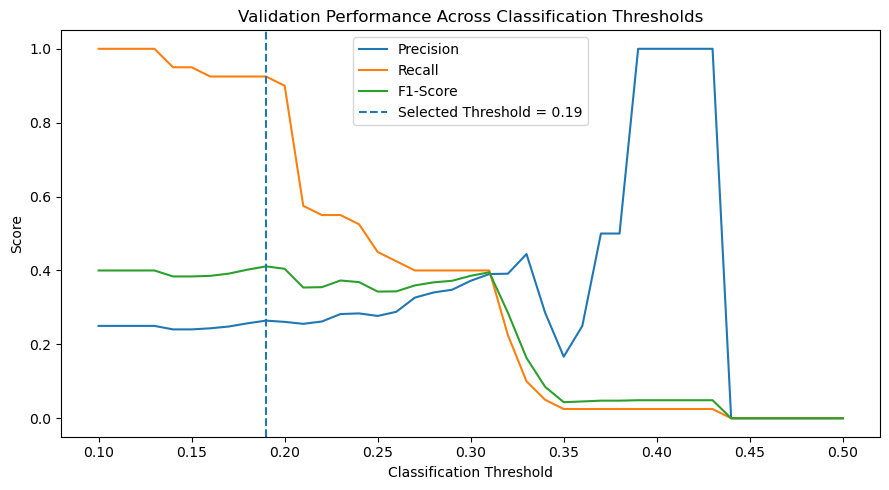

In [77]:
# ---------------------------------------------------------
# 70. VISUALISE PERFORMANCE ACROSS THRESHOLDS
# ---------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_results_df["Threshold"],
    threshold_results_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_results_df["Threshold"],
    threshold_results_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_results_df["Threshold"],
    threshold_results_df["F1-Score"],
    label="F1-Score"
)

plt.axvline(
    BEST_BASELINE_THRESHOLD,
    linestyle="--",
    label=f"Selected Threshold = {BEST_BASELINE_THRESHOLD:.2f}"
)

plt.title(
    "Validation Performance Across Classification Thresholds"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")

plt.legend()
plt.tight_layout()
plt.show()

In [78]:
# ---------------------------------------------------------
# 71. EVALUATE THRESHOLD-ADJUSTED BASELINE
# ---------------------------------------------------------

threshold_baseline_predictions = predict_class(
    X_val_np,
    baseline_weights,
    baseline_bias,
    threshold=BEST_BASELINE_THRESHOLD
)

threshold_baseline_metrics, threshold_baseline_confusion = (
    evaluate_binary_classifier(
        y_val_np,
        threshold_baseline_predictions,
        baseline_val_probabilities
    )
)

print("THRESHOLD-ADJUSTED BASELINE PERFORMANCE")
print("-" * 60)

display(
    threshold_baseline_metrics.assign(
        Score=lambda x: x["Score"].round(4)
    )
)

print("\nCONFUSION MATRIX COUNTS")
print("-" * 60)

for key, value in threshold_baseline_confusion.items():
    print(f"{key}: {value}")

THRESHOLD-ADJUSTED BASELINE PERFORMANCE
------------------------------------------------------------


,Metric,Score
0,Accuracy,0.3375
1,Balanced Accuracy,0.5333
2,Precision,0.2643
3,Recall,0.9250
4,Specificity,0.1417
5,F1-Score,0.4111
6,ROC-AUC,0.5724



CONFUSION MATRIX COUNTS
------------------------------------------------------------
TN: 17
FP: 103
FN: 3
TP: 37


### 7.3 Class-Weighted Logistic Regression

Threshold adjustment changes how probabilities are converted into classes but does not change what the model learns.

A second improvement therefore modifies the training objective itself. Balanced class weights are calculated from the training partition so that errors involving the minority bestseller class contribute more strongly to the optimisation process.

The weights are calculated using:

\[
w_c = \frac{N}{K \times N_c}
\]

where:

- \(N\) is the total number of training observations;
- \(K\) is the number of target classes; and
- \(N_c\) is the number of training observations in class \(c\).

Class weights are calculated using the training data only.

In [79]:
# ---------------------------------------------------------
# 72. CALCULATE BALANCED CLASS WEIGHTS
# ---------------------------------------------------------

n_train = len(y_train_np)

n_negative = np.sum(
    y_train_np == 0
)

n_positive = np.sum(
    y_train_np == 1
)

negative_weight = (
    n_train /
    (2 * n_negative)
)

positive_weight = (
    n_train /
    (2 * n_positive)
)

print("BALANCED CLASS WEIGHTS")
print("-" * 60)

print(
    f"Non-Bestseller observations: "
    f"{n_negative}"
)

print(
    f"Bestseller observations: "
    f"{n_positive}"
)

print(
    f"\nNon-Bestseller weight: "
    f"{negative_weight:.4f}"
)

print(
    f"Bestseller weight: "
    f"{positive_weight:.4f}"
)

BALANCED CLASS WEIGHTS
------------------------------------------------------------
Non-Bestseller observations: 561
Bestseller observations: 188

Non-Bestseller weight: 0.6676
Bestseller weight: 1.9920


In [80]:
# ---------------------------------------------------------
# 73. IMPLEMENT WEIGHTED BINARY CROSS-ENTROPY
# ---------------------------------------------------------

def weighted_binary_cross_entropy(
    y_true,
    y_probability,
    negative_weight,
    positive_weight
):
    """
    Calculate class-weighted binary cross-entropy.
    """
    
    epsilon = 1e-15
    
    y_probability = np.clip(
        y_probability,
        epsilon,
        1 - epsilon
    )
    
    sample_weights = np.where(
        y_true == 1,
        positive_weight,
        negative_weight
    )
    
    weighted_loss = -np.mean(
        sample_weights * (
            y_true * np.log(y_probability)
            +
            (1 - y_true) *
            np.log(1 - y_probability)
        )
    )
    
    return weighted_loss

In [81]:
# ---------------------------------------------------------
# 74. IMPLEMENT WEIGHTED GRADIENTS
# ---------------------------------------------------------

def compute_weighted_gradients(
    X,
    y,
    probabilities,
    negative_weight,
    positive_weight
):
    """
    Calculate class-weighted gradients.
    """
    
    m = X.shape[0]
    
    sample_weights = np.where(
        y == 1,
        positive_weight,
        negative_weight
    )
    
    weighted_errors = (
        sample_weights *
        (probabilities - y)
    )
    
    dw = (
        (1 / m) *
        (X.T @ weighted_errors)
    )
    
    db = (
        (1 / m) *
        np.sum(weighted_errors)
    )
    
    return dw, db

In [82]:
# ---------------------------------------------------------
# 75. IMPLEMENT CLASS-WEIGHTED TRAINING
# ---------------------------------------------------------

def train_weighted_logistic_regression(
    X_train,
    y_train,
    X_val,
    y_val,
    negative_weight,
    positive_weight,
    learning_rate=0.05,
    iterations=5000
):
    """
    Train class-weighted Logistic Regression
    using batch gradient descent.
    """
    
    n_features = X_train.shape[1]
    
    weights = np.zeros(n_features)
    bias = 0.0
    
    training_loss_history = []
    validation_loss_history = []
    
    for iteration in range(iterations):
        
        # Forward pass
        train_probabilities = sigmoid(
            X_train @ weights + bias
        )
        
        # Weighted training loss
        train_loss = weighted_binary_cross_entropy(
            y_train,
            train_probabilities,
            negative_weight,
            positive_weight
        )
        
        training_loss_history.append(
            train_loss
        )
        
        # Weighted gradients
        dw, db = compute_weighted_gradients(
            X_train,
            y_train,
            train_probabilities,
            negative_weight,
            positive_weight
        )
        
        # Parameter updates
        weights -= learning_rate * dw
        bias -= learning_rate * db
        
        # Validation probability
        val_probabilities = sigmoid(
            X_val @ weights + bias
        )
        
        # Use ordinary BCE for validation monitoring
        # because validation performance should reflect
        # natural class proportions.
        val_loss = binary_cross_entropy(
            y_val,
            val_probabilities
        )
        
        validation_loss_history.append(
            val_loss
        )
    
    return {
        "weights": weights,
        "bias": bias,
        "training_loss": training_loss_history,
        "validation_loss": validation_loss_history
    }

### 7.4 Class-Weighted Model Training

The weighted model uses the same learning rate and number of iterations as the baseline. Keeping the remaining training settings constant isolates the effect of class weighting and allows a controlled comparison between the two models.

In [83]:
# ---------------------------------------------------------
# 76. TRAIN CLASS-WEIGHTED MODEL
# ---------------------------------------------------------

weighted_model = train_weighted_logistic_regression(
    X_train=X_train_np,
    y_train=y_train_np,
    X_val=X_val_np,
    y_val=y_val_np,
    negative_weight=negative_weight,
    positive_weight=positive_weight,
    learning_rate=BASELINE_LEARNING_RATE,
    iterations=BASELINE_ITERATIONS
)

weighted_weights = weighted_model["weights"]
weighted_bias = weighted_model["bias"]

print("CLASS-WEIGHTED TRAINING COMPLETED")
print("-" * 60)

print(
    f"Initial weighted training loss: "
    f"{weighted_model['training_loss'][0]:.6f}"
)

print(
    f"Final weighted training loss:   "
    f"{weighted_model['training_loss'][-1]:.6f}"
)

print(
    f"Final validation loss:          "
    f"{weighted_model['validation_loss'][-1]:.6f}"
)

print(
    f"\nLearned intercept: "
    f"{weighted_bias:.6f}"
)

CLASS-WEIGHTED TRAINING COMPLETED
------------------------------------------------------------
Initial weighted training loss: 0.693147
Final weighted training loss:   0.673968
Final validation loss:          0.679580

Learned intercept: 0.586209


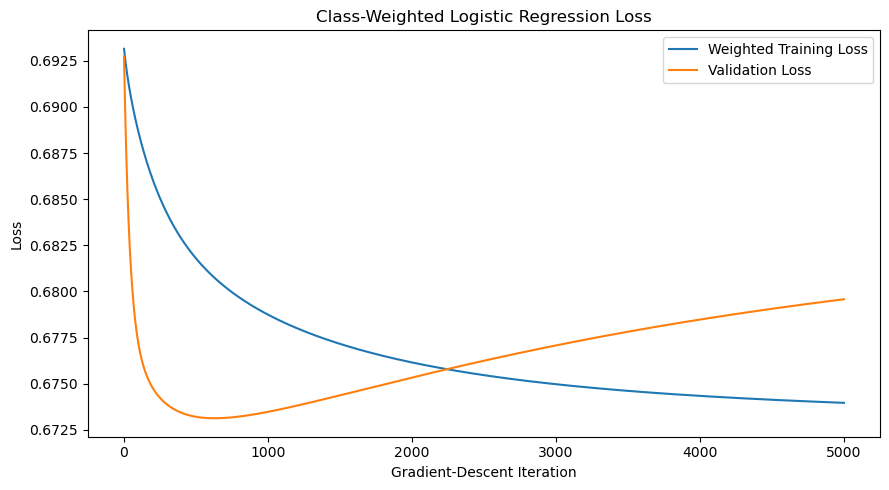

In [84]:
# ---------------------------------------------------------
# 77. PLOT WEIGHTED MODEL LOSS
# ---------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    weighted_model["training_loss"],
    label="Weighted Training Loss"
)

plt.plot(
    weighted_model["validation_loss"],
    label="Validation Loss"
)

plt.title(
    "Class-Weighted Logistic Regression Loss"
)

plt.xlabel("Gradient-Descent Iteration")
plt.ylabel("Loss")

plt.legend()
plt.tight_layout()
plt.show()

In [85]:
# ---------------------------------------------------------
# 78. EVALUATE CLASS-WEIGHTED MODEL
# ---------------------------------------------------------

weighted_val_probabilities = predict_probability(
    X_val_np,
    weighted_weights,
    weighted_bias
)

weighted_val_predictions = predict_class(
    X_val_np,
    weighted_weights,
    weighted_bias,
    threshold=0.50
)

weighted_validation_metrics, weighted_confusion = (
    evaluate_binary_classifier(
        y_val_np,
        weighted_val_predictions,
        weighted_val_probabilities
    )
)

print("CLASS-WEIGHTED VALIDATION PERFORMANCE")
print("-" * 60)

display(
    weighted_validation_metrics.assign(
        Score=lambda x: x["Score"].round(4)
    )
)

print("\nCONFUSION MATRIX COUNTS")
print("-" * 60)

for key, value in weighted_confusion.items():
    print(f"{key}: {value}")

CLASS-WEIGHTED VALIDATION PERFORMANCE
------------------------------------------------------------


,Metric,Score
0,Accuracy,0.5562
1,Balanced Accuracy,0.5375
2,Precision,0.2817
3,Recall,0.5000
4,Specificity,0.5750
5,F1-Score,0.3604
6,ROC-AUC,0.5768



CONFUSION MATRIX COUNTS
------------------------------------------------------------
TN: 69
FP: 51
FN: 20
TP: 20


### 7.5 Interpretation of Initial Improvement Experiments

Threshold adjustment substantially increased the baseline model's ability to identify bestsellers. At the validation-selected threshold of 0.19, recall increased to 0.9250 and F1-score improved to 0.4111. However, specificity fell to 0.1417 because many non-bestsellers were incorrectly classified as bestsellers.

Class weighting produced a more balanced classifier at the default threshold of 0.50. The weighted model achieved a balanced accuracy of 0.5375, recall of 0.5000 and specificity of 0.5750. Its ROC-AUC also increased slightly from 0.5724 to 0.5768.

The class-weighted training curve nevertheless showed that validation loss reached its minimum substantially before the final training iteration and then gradually increased while training loss continued to decline. This indicates that extended optimisation was beginning to overfit the training data.

A further controlled experiment therefore introduces early stopping to retain the parameter values associated with the lowest validation loss, followed by validation-based threshold optimisation.

In [86]:
# ---------------------------------------------------------
# 79. IMPLEMENT CLASS-WEIGHTED TRAINING WITH EARLY STOPPING
# ---------------------------------------------------------

def train_weighted_logistic_regression_early_stopping(
    X_train,
    y_train,
    X_val,
    y_val,
    negative_weight,
    positive_weight,
    learning_rate=0.05,
    max_iterations=5000,
    patience=250,
    min_delta=1e-6
):
    """
    Train class-weighted Logistic Regression using
    batch gradient descent with validation-based
    early stopping.
    """

    n_features = X_train.shape[1]

    weights = np.zeros(n_features)
    bias = 0.0

    training_loss_history = []
    validation_loss_history = []

    best_validation_loss = np.inf
    best_weights = weights.copy()
    best_bias = bias
    best_iteration = 0

    patience_counter = 0

    for iteration in range(max_iterations):

        # Training probabilities
        train_probabilities = sigmoid(
            X_train @ weights + bias
        )

        # Weighted training loss
        train_loss = weighted_binary_cross_entropy(
            y_train,
            train_probabilities,
            negative_weight,
            positive_weight
        )

        training_loss_history.append(train_loss)

        # Weighted gradients
        dw, db = compute_weighted_gradients(
            X_train,
            y_train,
            train_probabilities,
            negative_weight,
            positive_weight
        )

        # Update parameters
        weights -= learning_rate * dw
        bias -= learning_rate * db

        # Validation probabilities
        val_probabilities = sigmoid(
            X_val @ weights + bias
        )

        # Unweighted validation loss
        val_loss = binary_cross_entropy(
            y_val,
            val_probabilities
        )

        validation_loss_history.append(val_loss)

        # Check for validation improvement
        if val_loss < best_validation_loss - min_delta:

            best_validation_loss = val_loss
            best_weights = weights.copy()
            best_bias = bias
            best_iteration = iteration + 1

            patience_counter = 0

        else:

            patience_counter += 1

        # Early stopping condition
        if patience_counter >= patience:
            break

    return {
        "weights": best_weights,
        "bias": best_bias,
        "training_loss": training_loss_history,
        "validation_loss": validation_loss_history,
        "best_validation_loss": best_validation_loss,
        "best_iteration": best_iteration,
        "iterations_completed": iteration + 1
    }

### 7.6 Early-Stopped Class-Weighted Training

Early stopping is introduced to prevent unnecessary optimisation after validation performance has stopped improving.

The maximum training limit remains 5,000 iterations, but the algorithm retains the weights associated with the lowest validation loss. Training stops if validation loss fails to improve meaningfully for 250 consecutive iterations.

This approach uses validation information only for model development; the held-out test set remains untouched.

In [87]:
# ---------------------------------------------------------
# 80. TRAIN EARLY-STOPPED WEIGHTED MODEL
# ---------------------------------------------------------

early_weighted_model = (
    train_weighted_logistic_regression_early_stopping(
        X_train=X_train_np,
        y_train=y_train_np,
        X_val=X_val_np,
        y_val=y_val_np,
        negative_weight=negative_weight,
        positive_weight=positive_weight,
        learning_rate=BASELINE_LEARNING_RATE,
        max_iterations=5000,
        patience=250
    )
)

early_weighted_weights = (
    early_weighted_model["weights"]
)

early_weighted_bias = (
    early_weighted_model["bias"]
)

print("EARLY-STOPPED CLASS-WEIGHTED TRAINING")
print("-" * 60)

print(
    f"Best iteration: "
    f"{early_weighted_model['best_iteration']}"
)

print(
    f"Iterations completed: "
    f"{early_weighted_model['iterations_completed']}"
)

print(
    f"Best validation loss: "
    f"{early_weighted_model['best_validation_loss']:.6f}"
)

print(
    f"Learned intercept: "
    f"{early_weighted_bias:.6f}"
)

EARLY-STOPPED CLASS-WEIGHTED TRAINING
------------------------------------------------------------
Best iteration: 618
Iterations completed: 868
Best validation loss: 0.673134
Learned intercept: 0.205888


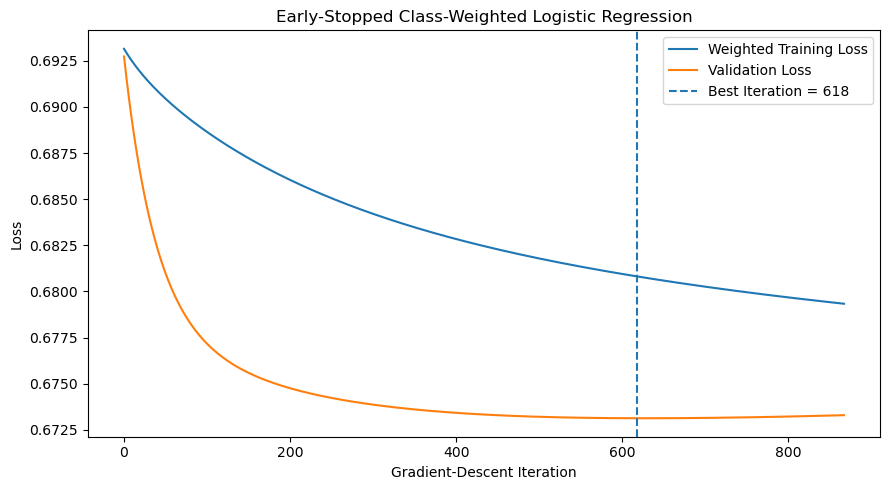

In [88]:
# ---------------------------------------------------------
# 81. VISUALISE EARLY-STOPPED TRAINING
# ---------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    early_weighted_model["training_loss"],
    label="Weighted Training Loss"
)

plt.plot(
    early_weighted_model["validation_loss"],
    label="Validation Loss"
)

plt.axvline(
    early_weighted_model["best_iteration"],
    linestyle="--",
    label=(
        f"Best Iteration = "
        f"{early_weighted_model['best_iteration']}"
    )
)

plt.title(
    "Early-Stopped Class-Weighted Logistic Regression"
)

plt.xlabel("Gradient-Descent Iteration")
plt.ylabel("Loss")

plt.legend()
plt.tight_layout()
plt.show()

In [89]:
# ---------------------------------------------------------
# 82. EVALUATE EARLY-STOPPED MODEL AT DEFAULT THRESHOLD
# ---------------------------------------------------------

early_weighted_val_probabilities = predict_probability(
    X_val_np,
    early_weighted_weights,
    early_weighted_bias
)

early_weighted_val_predictions = predict_class(
    X_val_np,
    early_weighted_weights,
    early_weighted_bias,
    threshold=0.50
)

early_weighted_metrics, early_weighted_confusion = (
    evaluate_binary_classifier(
        y_val_np,
        early_weighted_val_predictions,
        early_weighted_val_probabilities
    )
)

print("EARLY-STOPPED WEIGHTED VALIDATION PERFORMANCE")
print("-" * 60)

display(
    early_weighted_metrics.assign(
        Score=lambda x: x["Score"].round(4)
    )
)

print("\nCONFUSION MATRIX COUNTS")
print("-" * 60)

for key, value in early_weighted_confusion.items():
    print(f"{key}: {value}")

EARLY-STOPPED WEIGHTED VALIDATION PERFORMANCE
------------------------------------------------------------


,Metric,Score
0,Accuracy,0.6125
1,Balanced Accuracy,0.5833
2,Precision,0.3281
3,Recall,0.5250
4,Specificity,0.6417
5,F1-Score,0.4038
6,ROC-AUC,0.5864



CONFUSION MATRIX COUNTS
------------------------------------------------------------
TN: 77
FP: 43
FN: 19
TP: 21


In [90]:
# ---------------------------------------------------------
# 83. OPTIMISE THRESHOLD FOR EARLY-STOPPED WEIGHTED MODEL
# ---------------------------------------------------------

early_weighted_threshold_results = []

for threshold in threshold_values:

    predictions = (
        early_weighted_val_probabilities >= threshold
    ).astype(int)

    early_weighted_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_val_np,
            predictions
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val_np,
            predictions
        ),
        "Precision": precision_score(
            y_val_np,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val_np,
            predictions,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_val_np,
            predictions,
            zero_division=0
        )
    })


early_weighted_threshold_df = pd.DataFrame(
    early_weighted_threshold_results
)


best_early_threshold_row = (
    early_weighted_threshold_df
    .sort_values(
        by=[
            "F1-Score",
            "Balanced Accuracy"
        ],
        ascending=False
    )
    .iloc[0]
)


BEST_WEIGHTED_THRESHOLD = (
    best_early_threshold_row["Threshold"]
)


print("BEST EARLY-WEIGHTED VALIDATION THRESHOLD")
print("-" * 60)

print(
    f"Threshold: "
    f"{BEST_WEIGHTED_THRESHOLD:.2f}"
)

print(
    f"F1-Score: "
    f"{best_early_threshold_row['F1-Score']:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{best_early_threshold_row['Balanced Accuracy']:.4f}"
)

print(
    f"Precision: "
    f"{best_early_threshold_row['Precision']:.4f}"
)

print(
    f"Recall: "
    f"{best_early_threshold_row['Recall']:.4f}"
)

BEST EARLY-WEIGHTED VALIDATION THRESHOLD
------------------------------------------------------------
Threshold: 0.44
F1-Score: 0.4186
Balanced Accuracy: 0.5500
Precision: 0.2727
Recall: 0.9000


In [91]:
# ---------------------------------------------------------
# 84. EVALUATE IMPROVED WEIGHTED MODEL
# ---------------------------------------------------------

improved_val_predictions = predict_class(
    X_val_np,
    early_weighted_weights,
    early_weighted_bias,
    threshold=BEST_WEIGHTED_THRESHOLD
)

improved_validation_metrics, improved_confusion = (
    evaluate_binary_classifier(
        y_val_np,
        improved_val_predictions,
        early_weighted_val_probabilities
    )
)

print("IMPROVED MODEL VALIDATION PERFORMANCE")
print("-" * 60)

display(
    improved_validation_metrics.assign(
        Score=lambda x: x["Score"].round(4)
    )
)

print("\nCONFUSION MATRIX COUNTS")
print("-" * 60)

for key, value in improved_confusion.items():
    print(f"{key}: {value}")

IMPROVED MODEL VALIDATION PERFORMANCE
------------------------------------------------------------


,Metric,Score
0,Accuracy,0.3750
1,Balanced Accuracy,0.5500
2,Precision,0.2727
3,Recall,0.9000
4,Specificity,0.2000
5,F1-Score,0.4186
6,ROC-AUC,0.5864



CONFUSION MATRIX COUNTS
------------------------------------------------------------
TN: 24
FP: 96
FN: 4
TP: 36


In [92]:
# ---------------------------------------------------------
# 85. COMPARE MODEL-DEVELOPMENT EXPERIMENTS
# ---------------------------------------------------------

def metric_value(metrics_df, metric_name):
    return float(
        metrics_df.loc[
            metrics_df["Metric"] == metric_name,
            "Score"
        ].iloc[0]
    )


model_comparison = pd.DataFrame({
    "Model": [
        "Baseline (Threshold 0.50)",
        f"Baseline (Threshold {BEST_BASELINE_THRESHOLD:.2f})",
        "Class-Weighted (Threshold 0.50)",
        f"Early-Weighted (Threshold {BEST_WEIGHTED_THRESHOLD:.2f})"
    ],

    "Accuracy": [
        metric_value(
            baseline_validation_metrics,
            "Accuracy"
        ),
        metric_value(
            threshold_baseline_metrics,
            "Accuracy"
        ),
        metric_value(
            weighted_validation_metrics,
            "Accuracy"
        ),
        metric_value(
            improved_validation_metrics,
            "Accuracy"
        )
    ],

    "Balanced Accuracy": [
        metric_value(
            baseline_validation_metrics,
            "Balanced Accuracy"
        ),
        metric_value(
            threshold_baseline_metrics,
            "Balanced Accuracy"
        ),
        metric_value(
            weighted_validation_metrics,
            "Balanced Accuracy"
        ),
        metric_value(
            improved_validation_metrics,
            "Balanced Accuracy"
        )
    ],

    "Precision": [
        metric_value(
            baseline_validation_metrics,
            "Precision"
        ),
        metric_value(
            threshold_baseline_metrics,
            "Precision"
        ),
        metric_value(
            weighted_validation_metrics,
            "Precision"
        ),
        metric_value(
            improved_validation_metrics,
            "Precision"
        )
    ],

    "Recall": [
        metric_value(
            baseline_validation_metrics,
            "Recall"
        ),
        metric_value(
            threshold_baseline_metrics,
            "Recall"
        ),
        metric_value(
            weighted_validation_metrics,
            "Recall"
        ),
        metric_value(
            improved_validation_metrics,
            "Recall"
        )
    ],

    "F1-Score": [
        metric_value(
            baseline_validation_metrics,
            "F1-Score"
        ),
        metric_value(
            threshold_baseline_metrics,
            "F1-Score"
        ),
        metric_value(
            weighted_validation_metrics,
            "F1-Score"
        ),
        metric_value(
            improved_validation_metrics,
            "F1-Score"
        )
    ],

    "ROC-AUC": [
        metric_value(
            baseline_validation_metrics,
            "ROC-AUC"
        ),
        metric_value(
            threshold_baseline_metrics,
            "ROC-AUC"
        ),
        metric_value(
            weighted_validation_metrics,
            "ROC-AUC"
        ),
        metric_value(
            improved_validation_metrics,
            "ROC-AUC"
        )
    ]
})

display(
    model_comparison.round(4)
)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Baseline (Threshold 0.50),0.7500,0.5000,0.0000,0.000,0.0000,0.5724
1,Baseline (Threshold 0.19),0.3375,0.5333,0.2643,0.925,0.4111,0.5724
2,Class-Weighted (Threshold 0.50),0.5562,0.5375,0.2817,0.500,0.3604,0.5768
3,Early-Weighted (Threshold 0.44),0.3750,0.5500,0.2727,0.900,0.4186,0.5864


### 7.7 Validation-Based Feature Reduction

The statistical screening identified `Author_Rating` as the only candidate predictor with a clear univariate association with bestseller status. The remaining predictors showed weak or statistically non-significant individual relationships.

A reduced Logistic Regression model is therefore evaluated using only `Author_Rating`.

This experiment tests whether removing weak predictors can simplify the model without reducing validation performance. The same class-weighting, early-stopping and threshold-selection procedures are retained so that the comparison focuses primarily on the effect of feature reduction.

In [93]:
# ---------------------------------------------------------
# 86. DEFINE REDUCED FEATURE SET
# ---------------------------------------------------------

reduced_features = [
    "Author_Rating"
]

X_train_reduced = X_train[
    reduced_features
].copy()

X_val_reduced = X_val[
    reduced_features
].copy()

X_test_reduced = X_test[
    reduced_features
].copy()

print("REDUCED FEATURE SET")
print("-" * 60)

for feature in reduced_features:
    print(f"- {feature}")

print(
    f"\nTraining observations: "
    f"{len(X_train_reduced):,}"
)

REDUCED FEATURE SET
------------------------------------------------------------
- Author_Rating

Training observations: 749


### 7.8 Reduced-Feature Preprocessing

The reduced predictor set contains only the categorical `Author_Rating` variable. One-hot encoding is fitted using the training partition only, with one category dropped as the reference level.

In [94]:
# ---------------------------------------------------------
# 87. PREPROCESS REDUCED FEATURE SET
# ---------------------------------------------------------

reduced_preprocessor = ColumnTransformer([
    (
        "categorical",
        OneHotEncoder(
            drop="first",
            handle_unknown="ignore",
            sparse_output=False
        ),
        reduced_features
    )
])

X_train_reduced_processed = (
    reduced_preprocessor.fit_transform(
        X_train_reduced
    )
)

X_val_reduced_processed = (
    reduced_preprocessor.transform(
        X_val_reduced
    )
)

X_test_reduced_processed = (
    reduced_preprocessor.transform(
        X_test_reduced
    )
)

print("REDUCED MODEL DIMENSIONS")
print("-" * 60)

print(
    f"Training:   "
    f"{X_train_reduced_processed.shape}"
)

print(
    f"Validation: "
    f"{X_val_reduced_processed.shape}"
)

print(
    f"Test:       "
    f"{X_test_reduced_processed.shape}"
)

REDUCED MODEL DIMENSIONS
------------------------------------------------------------
Training:   (749, 3)
Validation: (160, 3)
Test:       (161, 3)


In [95]:
# ---------------------------------------------------------
# 88. DISPLAY REDUCED PROCESSED FEATURES
# ---------------------------------------------------------

reduced_feature_names = (
    reduced_preprocessor
    .get_feature_names_out()
)

reduced_feature_names = [
    name.replace("categorical__", "")
    for name in reduced_feature_names
]

print("REDUCED PROCESSED FEATURES")
print("-" * 60)

for i, feature in enumerate(
    reduced_feature_names,
    start=1
):
    print(f"{i:>2}. {feature}")

REDUCED PROCESSED FEATURES
------------------------------------------------------------
 1. Author_Rating_Famous
 2. Author_Rating_Intermediate
 3. Author_Rating_Novice


In [96]:
# ---------------------------------------------------------
# 89. PREPARE REDUCED NUMPY MATRICES
# ---------------------------------------------------------

X_train_reduced_np = np.asarray(
    X_train_reduced_processed,
    dtype=float
)

X_val_reduced_np = np.asarray(
    X_val_reduced_processed,
    dtype=float
)

X_test_reduced_np = np.asarray(
    X_test_reduced_processed,
    dtype=float
)

print("Reduced NumPy matrices prepared successfully.")

Reduced NumPy matrices prepared successfully.


In [97]:
# ---------------------------------------------------------
# 90. TRAIN REDUCED EARLY-WEIGHTED MODEL
# ---------------------------------------------------------

reduced_model = (
    train_weighted_logistic_regression_early_stopping(
        X_train=X_train_reduced_np,
        y_train=y_train_np,
        X_val=X_val_reduced_np,
        y_val=y_val_np,
        negative_weight=negative_weight,
        positive_weight=positive_weight,
        learning_rate=BASELINE_LEARNING_RATE,
        max_iterations=5000,
        patience=250
    )
)

reduced_weights = reduced_model["weights"]
reduced_bias = reduced_model["bias"]

print("REDUCED MODEL TRAINING COMPLETED")
print("-" * 60)

print(
    f"Best iteration: "
    f"{reduced_model['best_iteration']}"
)

print(
    f"Best validation loss: "
    f"{reduced_model['best_validation_loss']:.6f}"
)

print(
    f"Number of learned weights: "
    f"{len(reduced_weights)}"
)

REDUCED MODEL TRAINING COMPLETED
------------------------------------------------------------
Best iteration: 643
Best validation loss: 0.674122
Number of learned weights: 3


In [98]:
# ---------------------------------------------------------
# 91. GENERATE REDUCED MODEL PROBABILITIES
# ---------------------------------------------------------

reduced_val_probabilities = predict_probability(
    X_val_reduced_np,
    reduced_weights,
    reduced_bias
)

print("REDUCED MODEL PROBABILITY RANGE")
print("-" * 60)

print(
    f"Minimum: "
    f"{reduced_val_probabilities.min():.4f}"
)

print(
    f"Maximum: "
    f"{reduced_val_probabilities.max():.4f}"
)

print(
    f"Mean: "
    f"{reduced_val_probabilities.mean():.4f}"
)

REDUCED MODEL PROBABILITY RANGE
------------------------------------------------------------
Minimum: 0.4559
Maximum: 0.5519
Mean: 0.4903


In [99]:
# ---------------------------------------------------------
# 92. OPTIMISE REDUCED MODEL THRESHOLD
# ---------------------------------------------------------

reduced_threshold_results = []

for threshold in threshold_values:

    predictions = (
        reduced_val_probabilities >= threshold
    ).astype(int)

    reduced_threshold_results.append({
        "Threshold": threshold,

        "Accuracy": accuracy_score(
            y_val_np,
            predictions
        ),

        "Balanced Accuracy":
            balanced_accuracy_score(
                y_val_np,
                predictions
            ),

        "Precision": precision_score(
            y_val_np,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_val_np,
            predictions,
            zero_division=0
        ),

        "F1-Score": f1_score(
            y_val_np,
            predictions,
            zero_division=0
        )
    })


reduced_threshold_df = pd.DataFrame(
    reduced_threshold_results
)


best_reduced_threshold_row = (
    reduced_threshold_df
    .sort_values(
        by=[
            "F1-Score",
            "Balanced Accuracy"
        ],
        ascending=False
    )
    .iloc[0]
)


BEST_REDUCED_THRESHOLD = (
    best_reduced_threshold_row["Threshold"]
)


print("BEST REDUCED-MODEL THRESHOLD")
print("-" * 60)

print(
    f"Threshold: "
    f"{BEST_REDUCED_THRESHOLD:.2f}"
)

print(
    f"F1-Score: "
    f"{best_reduced_threshold_row['F1-Score']:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{best_reduced_threshold_row['Balanced Accuracy']:.4f}"
)

print(
    f"Precision: "
    f"{best_reduced_threshold_row['Precision']:.4f}"
)

print(
    f"Recall: "
    f"{best_reduced_threshold_row['Recall']:.4f}"
)

BEST REDUCED-MODEL THRESHOLD
------------------------------------------------------------
Threshold: 0.46
F1-Score: 0.4158
Balanced Accuracy: 0.5958
Precision: 0.3443
Recall: 0.5250


In [100]:
# ---------------------------------------------------------
# 93. EVALUATE REDUCED MODEL
# ---------------------------------------------------------

reduced_val_predictions = (
    reduced_val_probabilities >=
    BEST_REDUCED_THRESHOLD
).astype(int)


reduced_validation_metrics, reduced_confusion = (
    evaluate_binary_classifier(
        y_val_np,
        reduced_val_predictions,
        reduced_val_probabilities
    )
)


print("REDUCED MODEL VALIDATION PERFORMANCE")
print("-" * 60)

display(
    reduced_validation_metrics.assign(
        Score=lambda x:
        x["Score"].round(4)
    )
)


print("\nCONFUSION MATRIX COUNTS")
print("-" * 60)

for key, value in reduced_confusion.items():
    print(f"{key}: {value}")

REDUCED MODEL VALIDATION PERFORMANCE
------------------------------------------------------------


,Metric,Score
0,Accuracy,0.6312
1,Balanced Accuracy,0.5958
2,Precision,0.3443
3,Recall,0.5250
4,Specificity,0.6667
5,F1-Score,0.4158
6,ROC-AUC,0.5971



CONFUSION MATRIX COUNTS
------------------------------------------------------------
TN: 80
FP: 40
FN: 19
TP: 21


In [101]:
# ---------------------------------------------------------
# 94. COMPARE FULL AND REDUCED MODELS
# ---------------------------------------------------------

feature_set_comparison = pd.DataFrame({
    "Model": [
        "Full Early-Weighted Model",
        "Reduced Author_Rating Model"
    ],

    "Processed Features": [
        len(processed_feature_names),
        len(reduced_feature_names)
    ],

    "Threshold": [
        BEST_WEIGHTED_THRESHOLD,
        BEST_REDUCED_THRESHOLD
    ],

    "Balanced Accuracy": [
        metric_value(
            improved_validation_metrics,
            "Balanced Accuracy"
        ),
        metric_value(
            reduced_validation_metrics,
            "Balanced Accuracy"
        )
    ],

    "Precision": [
        metric_value(
            improved_validation_metrics,
            "Precision"
        ),
        metric_value(
            reduced_validation_metrics,
            "Precision"
        )
    ],

    "Recall": [
        metric_value(
            improved_validation_metrics,
            "Recall"
        ),
        metric_value(
            reduced_validation_metrics,
            "Recall"
        )
    ],

    "F1-Score": [
        metric_value(
            improved_validation_metrics,
            "F1-Score"
        ),
        metric_value(
            reduced_validation_metrics,
            "F1-Score"
        )
    ],

    "ROC-AUC": [
        metric_value(
            improved_validation_metrics,
            "ROC-AUC"
        ),
        metric_value(
            reduced_validation_metrics,
            "ROC-AUC"
        )
    ]
})

display(
    feature_set_comparison.round(4)
)

,Model,Processed Features,Threshold,Balanced Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Full Early-Weighted Model,16,0.44,0.5500,0.2727,0.900,0.4186,0.5864
1,Reduced Author_Rating Model,3,0.46,0.5958,0.3443,0.525,0.4158,0.5971


### 7.9 Final Model Selection

The full early-stopped class-weighted Logistic Regression model was selected as the final model.

At its validation-optimised classification threshold of 0.44, the model achieved an F1-score of 0.4186, which was the highest F1-score among the evaluated configurations. The reduced `Author_Rating` model achieved a very similar F1-score of 0.4158 and stronger balanced accuracy and ROC-AUC, demonstrating that author rating contains much of the available predictive signal.

However, F1-score had been defined in advance as the primary model-selection metric because the bestseller class is under-represented and both false-positive and false-negative predictions are important. The full model was therefore retained to maintain consistency with the pre-defined selection strategy rather than changing the selection criterion after observing the results.

The final selected configuration uses:

- the complete leakage-controlled predictor set;
- class-weighted binary cross-entropy;
- validation-based early stopping;
- the parameter values associated with minimum validation loss; and
- a classification threshold of 0.44.

All model-selection decisions were completed using training and validation data only. The held-out test partition remained untouched until this point.

## 8. Final Model Evaluation

The selected Logistic Regression model is now evaluated once on the previously untouched test partition.

The test set contains 161 books and was not used for feature selection, preprocessing fitting, threshold optimisation, early-stopping decisions or model selection. It therefore provides the final estimate of model performance on unseen observations.

In [102]:
# ---------------------------------------------------------
# 95. GENERATE FINAL TEST PREDICTIONS
# ---------------------------------------------------------

final_test_probabilities = predict_probability(
    X_test_np,
    early_weighted_weights,
    early_weighted_bias
)

final_test_predictions = predict_class(
    X_test_np,
    early_weighted_weights,
    early_weighted_bias,
    threshold=BEST_WEIGHTED_THRESHOLD
)

print("FINAL TEST PREDICTIONS GENERATED")
print("-" * 60)

print(
    f"Classification threshold: "
    f"{BEST_WEIGHTED_THRESHOLD:.2f}"
)

print(
    f"Predicted non-bestsellers: "
    f"{np.sum(final_test_predictions == 0)}"
)

print(
    f"Predicted bestsellers: "
    f"{np.sum(final_test_predictions == 1)}"
)

FINAL TEST PREDICTIONS GENERATED
------------------------------------------------------------
Classification threshold: 0.44
Predicted non-bestsellers: 29
Predicted bestsellers: 132


### 8.1 Final Test Performance

The final model is evaluated using the same metrics applied during validation. Particular attention is given to F1-score, balanced accuracy, recall, specificity and ROC-AUC because the target classes are not evenly represented.

In [103]:
# ---------------------------------------------------------
# 96. EVALUATE FINAL MODEL ON TEST DATA
# ---------------------------------------------------------

final_test_metrics, final_test_confusion = (
    evaluate_binary_classifier(
        y_test_np,
        final_test_predictions,
        final_test_probabilities
    )
)

print("FINAL TEST PERFORMANCE")
print("-" * 60)

display(
    final_test_metrics.assign(
        Score=lambda x: x["Score"].round(4)
    )
)

print("\nCONFUSION MATRIX COUNTS")
print("-" * 60)

for key, value in final_test_confusion.items():
    print(f"{key}: {value}")

FINAL TEST PERFORMANCE
------------------------------------------------------------


,Metric,Score
0,Accuracy,0.3789
1,Balanced Accuracy,0.5533
2,Precision,0.2727
3,Recall,0.9000
4,Specificity,0.2066
5,F1-Score,0.4186
6,ROC-AUC,0.6728



CONFUSION MATRIX COUNTS
------------------------------------------------------------
TN: 25
FP: 96
FN: 4
TP: 36


### 8.2 Final Confusion Matrix

The confusion matrix is used to examine the types of classification errors produced by the final model on unseen books.

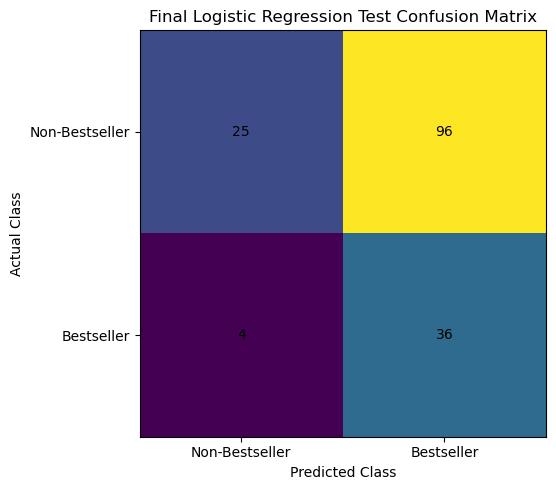

In [104]:
# ---------------------------------------------------------
# 97. PLOT FINAL TEST CONFUSION MATRIX
# ---------------------------------------------------------

final_cm = confusion_matrix(
    y_test_np,
    final_test_predictions,
    labels=[0, 1]
)

fig, ax = plt.subplots(
    figsize=(6, 5)
)

ax.imshow(final_cm)

ax.set_title(
    "Final Logistic Regression Test Confusion Matrix"
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

ax.set_xticks([0, 1])
ax.set_xticklabels([
    "Non-Bestseller",
    "Bestseller"
])

ax.set_yticks([0, 1])
ax.set_yticklabels([
    "Non-Bestseller",
    "Bestseller"
])

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            final_cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

### 8.3 Final ROC-AUC

The ROC curve evaluates the model's ability to rank unseen bestseller observations above non-bestsellers across all possible probability thresholds.

An ROC-AUC of 0.50 represents random ranking, while values increasingly above 0.50 indicate stronger discriminatory ability.

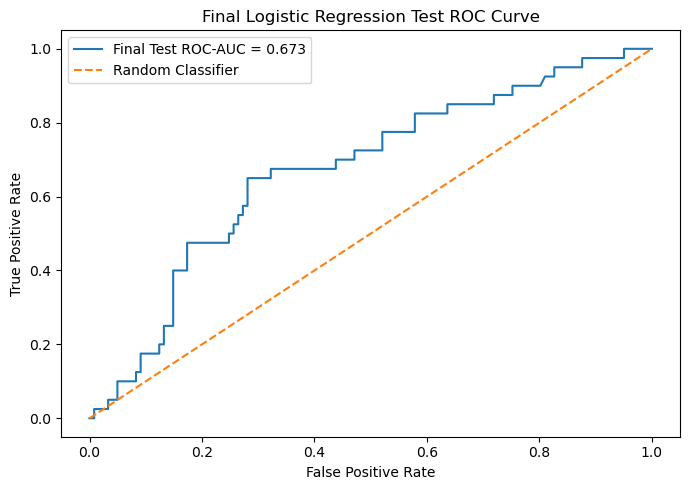

Final test ROC-AUC: 0.6728


In [105]:
# ---------------------------------------------------------
# 98. PLOT FINAL TEST ROC CURVE
# ---------------------------------------------------------

test_fpr, test_tpr, test_roc_thresholds = roc_curve(
    y_test_np,
    final_test_probabilities
)

final_test_auc = roc_auc_score(
    y_test_np,
    final_test_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    test_fpr,
    test_tpr,
    label=f"Final Test ROC-AUC = {final_test_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title(
    "Final Logistic Regression Test ROC Curve"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.tight_layout()
plt.show()

print(
    f"Final test ROC-AUC: "
    f"{final_test_auc:.4f}"
)

In [106]:
# ---------------------------------------------------------
# 99. COMPARE VALIDATION AND TEST PERFORMANCE
# ---------------------------------------------------------

validation_test_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision",
        "Recall",
        "Specificity",
        "F1-Score",
        "ROC-AUC"
    ],

    "Validation": [
        metric_value(
            improved_validation_metrics,
            "Accuracy"
        ),
        metric_value(
            improved_validation_metrics,
            "Balanced Accuracy"
        ),
        metric_value(
            improved_validation_metrics,
            "Precision"
        ),
        metric_value(
            improved_validation_metrics,
            "Recall"
        ),
        metric_value(
            improved_validation_metrics,
            "Specificity"
        ),
        metric_value(
            improved_validation_metrics,
            "F1-Score"
        ),
        metric_value(
            improved_validation_metrics,
            "ROC-AUC"
        )
    ],

    "Test": [
        metric_value(
            final_test_metrics,
            "Accuracy"
        ),
        metric_value(
            final_test_metrics,
            "Balanced Accuracy"
        ),
        metric_value(
            final_test_metrics,
            "Precision"
        ),
        metric_value(
            final_test_metrics,
            "Recall"
        ),
        metric_value(
            final_test_metrics,
            "Specificity"
        ),
        metric_value(
            final_test_metrics,
            "F1-Score"
        ),
        metric_value(
            final_test_metrics,
            "ROC-AUC"
        )
    ]
})

validation_test_comparison["Difference"] = (
    validation_test_comparison["Test"]
    -
    validation_test_comparison["Validation"]
)

display(
    validation_test_comparison.round(4)
)

,Metric,Validation,Test,Difference
0,Accuracy,0.3750,0.3789,0.0039
1,Balanced Accuracy,0.5500,0.5533,0.0033
2,Precision,0.2727,0.2727,0.0000
3,Recall,0.9000,0.9000,0.0000
4,Specificity,0.2000,0.2066,0.0066
5,F1-Score,0.4186,0.4186,0.0000
6,ROC-AUC,0.5864,0.6728,0.0865


### 8.4 Interpretation of Final Test Performance

The final model achieved a test F1-score of 0.4186, balanced accuracy of 0.5533 and ROC-AUC of 0.6728.

Its recall of 0.9000 shows that the model successfully identified 36 of the 40 actual bestsellers in the unseen test set. Only four bestseller observations were incorrectly classified as non-bestsellers.

This high sensitivity was achieved at the cost of substantially weaker specificity and precision. Of the 121 actual non-bestsellers, only 25 were correctly identified, while 96 were incorrectly classified as bestsellers. Precision was therefore 0.2727 and specificity 0.2066.

The final model is consequently better at avoiding missed bestsellers than at confidently separating bestsellers from non-bestsellers. From a publishing perspective, it may therefore be more useful as an initial screening model where failing to identify a potentially successful book is considered costly. It would be less appropriate as the sole basis for decisions involving limited marketing or acquisition resources because of its high false-positive rate.

The test ROC-AUC of 0.6728 also indicates that the model contains useful, although moderate, ranking information across probability thresholds. This was stronger than the validation ROC-AUC of 0.5864 and suggests that the learned probability ordering generalised reasonably to unseen observations.

### 8.5 Prediction Error Analysis

Individual test predictions are examined to understand the kinds of errors made by the final model.

False positives represent non-bestsellers that the model incorrectly identifies as bestsellers, while false negatives represent actual bestsellers that the model fails to identify.

In [107]:
# ---------------------------------------------------------
# 100. BUILD TEST ERROR-ANALYSIS DATASET
# ---------------------------------------------------------

test_results = clean_df.loc[
    X_test.index,
    [
        "Book Name",
        "Author",
        "Publishing Year",
        "Author_Rating",
        "genre",
        "sale price",
        "Publisher",
        "language_group",
        "units sold",
        "Bestseller"
    ]
].copy()

test_results["Predicted Probability"] = (
    final_test_probabilities
)

test_results["Predicted Class"] = (
    final_test_predictions
)

test_results["Error Type"] = np.select(
    [
        (test_results["Bestseller"] == 0) &
        (test_results["Predicted Class"] == 0),

        (test_results["Bestseller"] == 0) &
        (test_results["Predicted Class"] == 1),

        (test_results["Bestseller"] == 1) &
        (test_results["Predicted Class"] == 0),

        (test_results["Bestseller"] == 1) &
        (test_results["Predicted Class"] == 1)
    ],
    [
        "True Negative",
        "False Positive",
        "False Negative",
        "True Positive"
    ],
    default="Unknown"
)

print("TEST PREDICTION OUTCOMES")
print("-" * 60)

display(
    test_results["Error Type"]
    .value_counts()
    .to_frame(name="Count")
)

TEST PREDICTION OUTCOMES
------------------------------------------------------------


,Count
Error Type,
False Positive,96
True Positive,36
True Negative,25
False Negative,4


In [108]:
# ---------------------------------------------------------
# 101. INSPECT FALSE NEGATIVES
# ---------------------------------------------------------

false_negatives = (
    test_results[
        test_results["Error Type"] == "False Negative"
    ]
    .sort_values("Predicted Probability")
)

print("FALSE NEGATIVES")
print("-" * 60)

display(
    false_negatives[
        [
            "Book Name",
            "Author",
            "Author_Rating",
            "genre",
            "sale price",
            "Publisher",
            "units sold",
            "Predicted Probability"
        ]
    ].round(4)
)

FALSE NEGATIVES
------------------------------------------------------------


,Book Name,Author,Author_Rating,genre,sale price,Publisher,units sold,Predicted Probability
632,The Miserable Mill,"Lemony Snicket, Brett Helquist",Intermediate,fiction,10.99,Penguin Group (USA) LLC,46872,0.4208
646,Warm Bodies,Isaac Marion,Intermediate,fiction,3.99,"Amazon Digital Services, Inc.",43848,0.4328
624,The Amulet of Samarkand,Jonathan Stroud,Intermediate,fiction,0.99,"Amazon Digital Services, Inc.",47736,0.4384
658,The Monk Who Sold His Ferrari: A Fable About F...,Robin S. Sharma,Intermediate,fiction,0.99,"Amazon Digital Services, Inc.",40824,0.4386


In [109]:
# ---------------------------------------------------------
# 102. INSPECT HIGH-CONFIDENCE FALSE POSITIVES
# ---------------------------------------------------------

false_positives = (
    test_results[
        test_results["Error Type"] == "False Positive"
    ]
    .sort_values(
        "Predicted Probability",
        ascending=False
    )
)

print("TOP 10 HIGHEST-PROBABILITY FALSE POSITIVES")
print("-" * 60)

display(
    false_positives[
        [
            "Book Name",
            "Author",
            "Author_Rating",
            "genre",
            "sale price",
            "Publisher",
            "units sold",
            "Predicted Probability"
        ]
    ]
    .head(10)
    .round(4)
)

TOP 10 HIGHEST-PROBABILITY FALSE POSITIVES
------------------------------------------------------------


,Book Name,Author,Author_Rating,genre,sale price,Publisher,units sold,Predicted Probability
1053,Rosencrantz and Guildenstern are Dead,"Tom Stoppard, Henry Popkin",Excellent,nonfiction,12.59,Random House LLC,106,0.6389
456,A Monster Calls,"Patrick Ness, Jim Kay, Siobhan Dowd",Excellent,fiction,10.65,Random House LLC,4671,0.5991
833,Ð—Ð°Ð¿Ð¸ÑÐºÐ¸ Ð¸Ð· Ð¿Ð¾Ð´Ð¿Ð¾Ð»ÑŒÑ,"Fyodor Dostoyevsky, Andrew R. MacAndrew, Ben M...",Excellent,fiction,7.99,Random House LLC,2889,0.5983
942,"Lover Enshrined, part one",J.R. Ward,Excellent,fiction,8.99,Random House LLC,4320,0.5953
981,Twelve Years a Slave,Solomon Northup,Excellent,fiction,4.99,Random House LLC,4240,0.5917
1045,"Full Dark, No Stars",Stephen King,Excellent,fiction,5.99,Random House LLC,107,0.5882
297,Persepolis,"Marjane Satrapi, Mattias Ripa",Excellent,fiction,4.99,Random House LLC,298,0.5862
568,é“å¾·ç¶“ [dÃ o dÃ© jÄ«ng],"Lao Tzu, Gia-Fu Feng, Jane English, Chungliang...",Excellent,fiction,4.59,Penguin Group (USA) LLC,3915,0.5857
953,The Fall of Hyperion,Dan Simmons,Excellent,nonfiction,5.83,Simon and Schuster Digital Sales Inc,4280,0.5853
879,The Murder of Roger Ackroyd,Agatha Christie,Excellent,nonfiction,7.52,"Amazon Digital Services, Inc.",4440,0.5849


In [110]:
# ---------------------------------------------------------
# 103. SUMMARISE PROBABILITIES BY PREDICTION OUTCOME
# ---------------------------------------------------------

error_probability_summary = (
    test_results
    .groupby("Error Type")["Predicted Probability"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max"
    ])
    .round(4)
)

display(error_probability_summary)

,count,mean,median,min,max
Error Type,,,,,
False Negative,4,0.4327,0.4356,0.4208,0.4386
False Positive,96,0.4980,0.4904,0.4401,0.6389
True Negative,25,0.4280,0.4294,0.4044,0.4393
True Positive,36,0.5224,0.5358,0.4415,0.6134


The prediction probabilities show that many classification errors occurred close to the selected threshold of 0.44. The four false negatives received probabilities between 0.4208 and 0.4386, meaning that these actual bestsellers narrowly missed the classification boundary.

False positives had a higher mean predicted probability of 0.4980, with values ranging from 0.4401 to 0.6389. This indicates that some non-bestsellers were not merely borderline cases but were assigned relatively strong bestseller probabilities.

The error analysis therefore suggests that the model's limitations cannot be explained by the classification threshold alone. There is substantial overlap between the predictor patterns of bestsellers and non-bestsellers, which limits the model's ability to separate the two classes reliably.

## 9. Model Interpretation

Logistic Regression provides interpretable coefficients describing how each model feature affects the estimated log-odds of bestseller classification while the remaining predictors are held constant.

Before interpreting the dummy-variable coefficients, the reference categories used during one-hot encoding are identified.

In [111]:
# ---------------------------------------------------------
# 104. IDENTIFY CATEGORICAL REFERENCE LEVELS
# ---------------------------------------------------------

fitted_encoder = (
    preprocessor
    .named_transformers_["categorical"]
    .named_steps["encoder"]
)

print("CATEGORICAL REFERENCE LEVELS")
print("-" * 60)

for feature, categories, drop_index in zip(
    categorical_features,
    fitted_encoder.categories_,
    fitted_encoder.drop_idx_
):
    
    reference_category = categories[drop_index]
    
    print(
        f"{feature:<20} -> "
        f"Reference: {reference_category}"
    )

CATEGORICAL REFERENCE LEVELS
------------------------------------------------------------
Author_Rating        -> Reference: Excellent
genre                -> Reference: children
Publisher            -> Reference: Amazon Digital Services,  Inc.
language_group       -> Reference: English


### 9.1 Coefficients and Odds Ratios

A positive Logistic Regression coefficient increases the estimated log-odds of bestseller classification, while a negative coefficient decreases them.

Exponentiating each coefficient produces an odds ratio:

\[
OR = e^{\beta}
\]

An odds ratio greater than 1 indicates higher estimated bestseller odds, while a value below 1 indicates lower estimated odds, relative to the appropriate reference condition.

Because numerical predictors were standardised, their odds ratios represent the change associated with a one-standard-deviation increase rather than a one-unit increase in the original scale.

Because the final classifier was trained using class-weighted loss, these odds ratios describe relationships within the fitted weighted classification model. They should therefore be interpreted as model-based associations rather than population-level inferential odds ratios or evidence of causal effects.

In [112]:
# ---------------------------------------------------------
# 105. CALCULATE FINAL MODEL COEFFICIENTS AND ODDS RATIOS
# ---------------------------------------------------------

coefficient_table = pd.DataFrame({
    "Feature": processed_feature_names,
    "Coefficient": early_weighted_weights
})

coefficient_table["Odds Ratio"] = np.exp(
    coefficient_table["Coefficient"]
)

coefficient_table["Absolute Coefficient"] = (
    coefficient_table["Coefficient"].abs()
)

coefficient_table["Direction"] = np.where(
    coefficient_table["Coefficient"] > 0,
    "Higher bestseller odds",
    np.where(
        coefficient_table["Coefficient"] < 0,
        "Lower bestseller odds",
        "No change"
    )
)

coefficient_table = (
    coefficient_table
    .sort_values(
        "Absolute Coefficient",
        ascending=False
    )
)

display(
    coefficient_table[
        [
            "Feature",
            "Coefficient",
            "Odds Ratio",
            "Direction"
        ]
    ].round(4)
)

,Feature,Coefficient,Odds Ratio,Direction
3,Author_Rating_Intermediate,-0.3718,0.6895,Lower bestseller odds
2,Author_Rating_Famous,-0.1959,0.8221,Lower bestseller odds
12,Publisher_Random House LLC,0.1844,1.2026,Higher bestseller odds
11,Publisher_Penguin Group (USA) LLC,-0.1702,0.8435,Lower bestseller odds
6,genre_nonfiction,0.1051,1.1108,Higher bestseller odds
4,Author_Rating_Novice,-0.0998,0.9050,Lower bestseller odds
10,Publisher_Macmillan,-0.0923,0.9118,Lower bestseller odds
7,Publisher_Hachette Book Group,0.0840,1.0877,Higher bestseller odds
15,language_group_Unknown,-0.0508,0.9505,Lower bestseller odds
9,Publisher_HarperCollins Publishers,-0.0465,0.9546,Lower bestseller odds


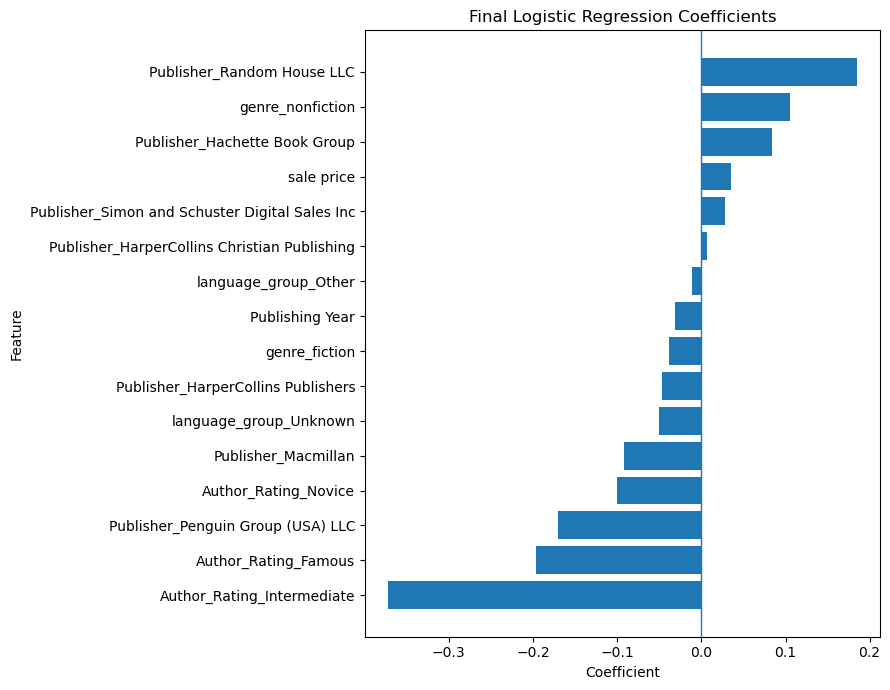

In [113]:
# ---------------------------------------------------------
# 106. VISUALISE FINAL MODEL COEFFICIENTS
# ---------------------------------------------------------

coefficient_plot = (
    coefficient_table
    .sort_values("Coefficient")
)

plt.figure(figsize=(9, 7))

plt.barh(
    coefficient_plot["Feature"],
    coefficient_plot["Coefficient"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.title(
    "Final Logistic Regression Coefficients"
)

plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### 9.2 Interpretation of the Strongest Model Effects

The coefficient analysis indicates that author rating contributes some of the strongest differences in predicted bestseller odds.

`Excellent` is the reference category for `Author_Rating`. Relative to this group, books associated with `Intermediate` authors have a coefficient of approximately -0.3718 and an odds ratio of approximately 0.6895. Within the fitted model, this corresponds to lower estimated bestseller odds relative to the Excellent reference group when the remaining model features are held constant.

The `Famous` and `Novice` categories also have negative coefficients relative to the Excellent reference level, which is broadly consistent with the earlier exploratory finding that the Excellent author category recorded the highest observed bestseller rate.

Several publisher coefficients show smaller positive or negative effects relative to Amazon Digital Services, Inc., which is the publisher reference category. For example, Random House LLC has a positive coefficient, whereas Penguin Group (USA) LLC has a negative coefficient.

The coefficients for sale price and publishing year are comparatively small. Because these numerical predictors were standardised before model training, their odds ratios represent changes associated with one standard deviation rather than one unit in the original measurement scale.

These coefficients describe associations learned by the fitted class-weighted model and should not be interpreted as evidence that any characteristic causes a book to become a bestseller.

## 10. Limitations

Several limitations should be considered when interpreting the model.

First, the source dataset does not provide an official binary bestseller label. Bestseller status was operationally defined as membership in the highest-selling 25% of books according to observed units sold. The model therefore predicts high sales relative to this particular dataset rather than membership in an external industry bestseller list.

Second, the available leakage-safe predictors contain limited information about actual commercial success. Reader ratings, rating counts, gross sales, publisher revenue, sales rank and units sold were excluded because they either reveal the outcome directly or become available after commercial performance has already occurred. Removing these variables produces a more realistic prediction problem but substantially reduces predictive signal.

Third, the selected classification threshold prioritised F1-score and resulted in high recall but a large number of false-positive predictions. The model identified most actual bestsellers but incorrectly classified many non-bestsellers as successful.

Fourth, some categorical groups contain relatively few observations. For example, the children's genre contains only 15 books, and some language and publisher categories are also small. Coefficients involving these categories should therefore be interpreted cautiously.

Fifth, the dataset represents a particular collection of books, publishers and historical periods. The fitted relationships may not generalise to all contemporary publishing markets.

Finally, Logistic Regression assumes that predictors influence the log-odds of the target through an additive linear structure. More complex relationships or interactions may therefore remain uncaptured.

## 11. Overall Conclusion

This project developed a binary Logistic Regression classifier entirely from scratch using NumPy to investigate whether book characteristics could be used to identify books with high sales performance.

The analysis began with a detailed audit of 1,070 book records. Data-quality issues, target leakage and temporal leakage were considered before modelling. Bestseller status was operationally defined as sales above the 75th percentile, resulting in 268 bestsellers and 802 non-bestsellers.

Exploratory analysis showed that most available predictors had relatively weak individual relationships with bestseller status. Author rating produced the clearest categorical association and remained influential during model interpretation.

The initial Logistic Regression model performed no better than the majority-class benchmark at the default threshold of 0.50. Controlled model improvement therefore introduced threshold optimisation, class weighting, early stopping and feature-selection experiments. The final model was selected using validation F1-score before the test set was evaluated.

On the unseen test set, the selected model achieved an F1-score of 0.4186, balanced accuracy of 0.5533 and ROC-AUC of 0.6728. Recall was high at 0.9000, meaning that 36 of 40 actual bestsellers were correctly identified. However, precision remained low at 0.2727 because the model also produced a substantial number of false-positive predictions.

The results demonstrate that Logistic Regression can identify some useful patterns in the available pre-outcome book characteristics, but the predictors are insufficient for highly accurate bestseller classification. The model is therefore most appropriately interpreted as an exploratory screening tool rather than a definitive commercial forecasting system.

Overall, the analysis demonstrates the complete development of a Logistic Regression classifier from mathematical formulation and gradient-descent optimisation through feature preparation, validation-based improvement, final test evaluation and interpretable coefficient analysis.